# Conveyor telemetry: EDA and modelling readiness

This notebook examines the historian export before any model training. It preserves
the imported records, audits repeated timestamps, and then constructs a documented
one-row-per-timestamp analysis view. It does **not** train an autoencoder, declare
faults, or remove outliers.

Scenario names are not recorded in the expected telemetry tags. Any scenario mapping
is an inference from the known execution order and measured telemetry, not a
historian-confirmed label. Units, timezone, and an intended query window were not
supplied; conclusions depending on them remain provisional.

## A. Load and inspect

The first pass reports the file and schema without changing or dropping source rows.
Set `CSV_PATH` if this notebook is run from another working directory.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
CSV_PATH = Path("conveyor_historian_export.csv")
EXPECTED = [
    "commandedSpeed", "conveyorLoad", "isMotorRunning", "motorCurrent",
    "roller_1_bearing_1_temp", "roller_1_bearing_1_vibration",
    "roller_1_bearing_2_temp", "roller_1_bearing_2_vibration",
    "roller_2_bearing_1_temp", "roller_2_bearing_1_vibration",
    "roller_2_bearing_2_temp", "roller_2_bearing_2_vibration",
]
BEARINGS = ["roller_1_bearing_1", "roller_1_bearing_2",
            "roller_2_bearing_1", "roller_2_bearing_2"]
if not CSV_PATH.is_file():
    raise FileNotFoundError(f"CSV not found: {CSV_PATH.resolve()}. Set CSV_PATH.")
raw = pd.read_csv(CSV_PATH)
print("CSV path:", CSV_PATH.resolve())
print("Shape:", raw.shape, "\nColumns:", raw.columns.tolist())
print("Dtypes:\n", raw.dtypes.to_string())
display(raw.head())
display(raw.tail())
print("Missing expected tags:", sorted(set(EXPECTED) - set(raw.columns)))
print("Unexpected columns:", sorted(set(raw.columns) - set(EXPECTED) - {"timestamp", "t_stamp"}))

CSV path: C:\UnityProjects\DigitalTwin-Project\ml\conveyor_historian_export.csv
Shape: (297876, 13) 
Columns: ['timestamp', 'commandedSpeed', 'conveyorLoad', 'isMotorRunning', 'motorCurrent', 'roller_1_bearing_1_temp', 'roller_1_bearing_1_vibration', 'roller_1_bearing_2_temp', 'roller_1_bearing_2_vibration', 'roller_2_bearing_1_temp', 'roller_2_bearing_1_vibration', 'roller_2_bearing_2_temp', 'roller_2_bearing_2_vibration']
Dtypes:
 timestamp                           str
commandedSpeed                  float64
conveyorLoad                    float64
isMotorRunning                    int64
motorCurrent                    float64
roller_1_bearing_1_temp         float64
roller_1_bearing_1_vibration    float64
roller_1_bearing_2_temp         float64
roller_1_bearing_2_vibration    float64
roller_2_bearing_1_temp         float64
roller_2_bearing_1_vibration    float64
roller_2_bearing_2_temp         float64
roller_2_bearing_2_vibration    float64


,timestamp,commandedSpeed,conveyorLoad,isMotorRunning,motorCurrent,roller_1_bearing_1_temp,roller_1_bearing_1_vibration,roller_1_bearing_2_temp,roller_1_bearing_2_vibration,roller_2_bearing_1_temp,roller_2_bearing_1_vibration,roller_2_bearing_2_temp,roller_2_bearing_2_vibration
0,2026-10-17 23:01:54.524,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2026-10-17 23:01:54.524,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2026-10-17 23:01:54.524,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0
3,2026-10-17 23:01:54.524,NaN,0.0,0,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,0.0
4,2026-10-17 23:01:54.524,NaN,0.0,0,NaN,NaN,NaN,NaN,0.0,NaN,0.0,NaN,0.0


,timestamp,commandedSpeed,conveyorLoad,isMotorRunning,motorCurrent,roller_1_bearing_1_temp,roller_1_bearing_1_vibration,roller_1_bearing_2_temp,roller_1_bearing_2_vibration,roller_2_bearing_1_temp,roller_2_bearing_1_vibration,roller_2_bearing_2_temp,roller_2_bearing_2_vibration
297871,2026-10-18 05:56:42.189,0.0,-0.000054,0,0.0,29.060921,0.0,29.377569,0.0,28.93594,0.0,29.28293,0.0
297872,2026-10-18 05:56:42.189,0.0,-0.000054,0,0.0,29.060921,0.0,29.377569,0.0,28.93594,0.0,29.28293,0.0
297873,2026-10-18 05:56:42.189,0.0,-0.000054,0,0.0,29.060921,0.0,29.377569,0.0,28.93594,0.0,29.28293,0.0
297874,2026-10-18 05:56:42.189,0.0,-0.000054,0,0.0,29.060921,0.0,29.377569,0.0,28.93594,0.0,29.28293,0.0
297875,2026-10-18 05:56:42.189,0.0,-0.000054,0,0.0,29.060921,0.0,29.377569,0.0,28.93594,0.0,29.28293,0.0


Missing expected tags: []
Unexpected columns: []


## A. Parse timestamps and audit source rows

Parsing errors and chronological order are reported, not hidden. `raw` remains
unchanged. The export has no timezone marker, so no timezone is assigned.

In [2]:
time_fields = [c for c in ("timestamp", "t_stamp") if c in raw.columns]
if len(time_fields) != 1:
    raise ValueError(f"Expected one timestamp or t_stamp field; found {time_fields}")
TIME_COL = time_fields[0]
parsed_time = pd.to_datetime(raw[TIME_COL], errors="coerce")
print("Timestamp field:", TIME_COL)
print("Parsing failures:", int(parsed_time.isna().sum()))
print("Chronological source order:", bool(parsed_time.dropna().is_monotonic_increasing))
print("First / last:", parsed_time.min(), "/", parsed_time.max())
print("Observation span:", parsed_time.max() - parsed_time.min())
print("Timezone: not specified in source; local/UTC interpretation is unknown.")
print("No intended collection window was supplied; out-of-window records cannot be tested.")
print("Exact duplicate rows:", int(raw.duplicated().sum()))
print("Rows with repeated timestamps:", int(parsed_time.duplicated(keep=False).sum()))

source = raw.loc[parsed_time.notna()].copy()
source["_time"] = parsed_time.loc[parsed_time.notna()]
values = [c for c in source.columns if c not in {TIME_COL, "_time"}]
groups = source.groupby("_time", sort=True)
rows_per_time = groups.size()
conflicts = groups[values].nunique(dropna=True).gt(1)
print("Unique parsed timestamps:", len(rows_per_time))
print("Timestamp groups with repeated rows:", int(rows_per_time.gt(1).sum()))
display(rows_per_time.value_counts().sort_index().rename_axis("rows").to_frame("groups"))
display(conflicts.sum().rename("timestamp_groups_with_multiple_values").to_frame())
dup_audit = pd.DataFrame({
    "rows": rows_per_time,
    "distinct_rows": groups[values].apply(lambda g: g.drop_duplicates().shape[0]),
    "conflicting_fields": conflicts.sum(axis=1),
})
display(dup_audit.sort_values(["conflicting_fields", "rows"], ascending=False).head(10))
print("Raw source missing values by column:")
display(raw.isna().sum().rename("missing").to_frame())

Timestamp field: timestamp
Parsing failures: 0
Chronological source order: True
First / last: 2026-10-17 23:01:54.524000 / 2026-10-18 05:56:42.189000
Observation span: 0 days 06:54:47.665000
Timezone: not specified in source; local/UTC interpretation is unknown.
No intended collection window was supplied; out-of-window records cannot be tested.


Exact duplicate rows: 47969
Rows with repeated timestamps: 297859


Unique parsed timestamps: 24852
Timestamp groups with repeated rows: 24835


,groups
rows,
1,17
2,3
3,4
4,2
5,2
6,2
7,2
8,2
9,4


,timestamp_groups_with_multiple_values
commandedSpeed,14
conveyorLoad,15789
isMotorRunning,0
motorCurrent,22156
roller_1_bearing_1_temp,24368
roller_1_bearing_1_vibration,22267
roller_1_bearing_2_temp,24353
roller_1_bearing_2_vibration,22248
roller_2_bearing_1_temp,24279
roller_2_bearing_1_vibration,22214


,rows,distinct_rows,conflicting_fields
_time,,,
2026-10-18 04:52:12.820,12,12,11
2026-10-18 05:51:19.623,12,12,11
2026-10-17 23:02:12.538,12,11,10
2026-10-17 23:02:15.540,12,11,10
2026-10-17 23:02:18.542,12,11,10
2026-10-17 23:02:20.544,12,11,10
2026-10-17 23:02:21.546,12,11,10
2026-10-17 23:02:23.547,12,11,10
2026-10-17 23:02:24.547,12,11,10


Raw source missing values by column:


,missing
timestamp,0
commandedSpeed,504
conveyorLoad,84
isMotorRunning,0
motorCurrent,840
roller_1_bearing_1_temp,924
roller_1_bearing_1_vibration,420
roller_1_bearing_2_temp,672
roller_1_bearing_2_vibration,336
roller_2_bearing_1_temp,588


### Construct the analysis time series

The source export may contain successive snapshots at the same timestamp. After
auditing this structure, the working view retains the last source row per timestamp.
This does not mutate `raw`; conversion errors remain measurable below.

In [3]:
working = source.drop_duplicates("_time", keep="last").set_index("_time").sort_index()
working.index.name = "timestamp"
print("Raw rows:", len(raw), "| parseable rows:", len(source),
      "| unique-time rows:", len(working))
print("Missing values after selecting final row in each timestamp group:")
display(working[values].isna().sum().rename("missing").to_frame())

df = working.copy()
for col in EXPECTED:
    if col in df:
        df[col] = pd.to_numeric(df[col], errors="coerce")
features = [c for c in EXPECTED if c in df and c != "isMotorRunning"]
print("Analysis time range:", df.index.min(), "to", df.index.max())

Raw rows: 297876 | parseable rows: 297876 | unique-time rows: 24852
Missing values after selecting final row in each timestamp group:


,missing
commandedSpeed,0
conveyorLoad,0
isMotorRunning,0
motorCurrent,0
roller_1_bearing_1_temp,0
roller_1_bearing_1_vibration,0
roller_1_bearing_2_temp,0
roller_1_bearing_2_vibration,0
roller_2_bearing_1_temp,0
roller_2_bearing_1_vibration,0


Analysis time range: 2026-10-17 23:01:54.524000 to 2026-10-18 05:56:42.189000


## B. Data quality and sampling interval

Missing/non-numeric/infinite values, constants, and negatives are counted. Units
and engineering limits are unknown, so negative/extreme values are review candidates,
not automatic failures. Timestamp gaps are assessed relative to the observed interval,
not Unity's configured interval.

In [4]:
quality_rows = []
for col in EXPECTED:
    if col not in working:
        continue
    original = working[col]
    numeric = pd.to_numeric(original, errors="coerce")
    arr = numeric.to_numpy(dtype=float, na_value=np.nan)
    quality_rows.append({
        "tag": col, "missing": int(original.isna().sum()),
        "missing_pct": 100 * original.isna().mean(),
        "non_numeric_non_null": int((original.notna() & numeric.isna()).sum()),
        "infinite": int(np.isinf(arr).sum()),
        "unique_non_null": int(numeric.nunique()),
        "negative": int(numeric.lt(0).sum()),
        "min": numeric.min(), "max": numeric.max(),
    })
quality = pd.DataFrame(quality_rows).set_index("tag")
display(quality.round(5))
print("Motor-running values:")
display(working["isMotorRunning"].value_counts(dropna=False).to_frame("count"))
print("Unexpected state values beyond {0, 1}:",
      sorted(set(df["isMotorRunning"].dropna().unique()) - {0, 1}))

,missing,missing_pct,non_numeric_non_null,infinite,unique_non_null,negative,min,max
tag,,,,,,,,
commandedSpeed,0,0.0,0,0,3,0,0.00000,0.75000
conveyorLoad,0,0.0,0,0,15545,1844,-0.00006,25.80947
isMotorRunning,0,0.0,0,0,2,0,0.00000,1.00000
motorCurrent,0,0.0,0,0,22126,0,0.00000,1.08219
roller_1_bearing_1_temp,0,0.0,0,0,23747,0,0.00000,38.68616
roller_1_bearing_1_vibration,0,0.0,0,0,22140,0,0.00000,1.64814
roller_1_bearing_2_temp,0,0.0,0,0,23728,0,0.00000,38.74586
roller_1_bearing_2_vibration,0,0.0,0,0,22130,0,0.00000,1.70739
roller_2_bearing_1_temp,0,0.0,0,0,23669,0,0.00000,39.00663


Motor-running values:


,count
isMotorRunning,
1,22701
0,2151


Unexpected state values beyond {0, 1}: []


Raw timestamp differences (seconds; includes repeated timestamps):


,seconds
count,297875.000000
mean,0.083551
std,0.277462
min,0.000000
50%,0.000000
90%,0.000000
99%,1.002000
max,7.205000


Unique-time positive intervals (seconds):


,seconds
count,24851.000000
mean,1.001475
std,0.059135
min,0.001000
50%,1.001000
90%,1.002000
99%,1.015000
max,7.205000


Median observed interval: 1.001 seconds
Unity configured interval from project notes: 0.25 s; observed median is 4.0x that value. Verify historian/export cadence rather than assuming 0.25 s samples.
Repeated-timestamp intervals in raw delta series: 273024


,threshold_s,count,elapsed_s
multiple,,,
1.5,1.5015,20,45.304
2.0,2.0020,5,15.298
5.0,5.0050,1,7.205
10.0,10.0100,0,0.000


,gap_seconds,estimated_missing_intervals
timestamp,,
2026-10-17 23:25:10.174,7.205,6.0
2026-10-17 23:25:12.236,2.062,1.0
2026-10-18 02:44:22.371,2.013,1.0
2026-10-18 02:36:42.083,2.009,1.0
2026-10-18 03:46:03.203,2.009,1.0
2026-10-18 05:21:15.051,2.001,1.0
2026-10-18 00:19:26.127,2.001,1.0
2026-10-18 03:51:11.962,2.001,1.0
2026-10-18 01:32:32.280,2.001,1.0


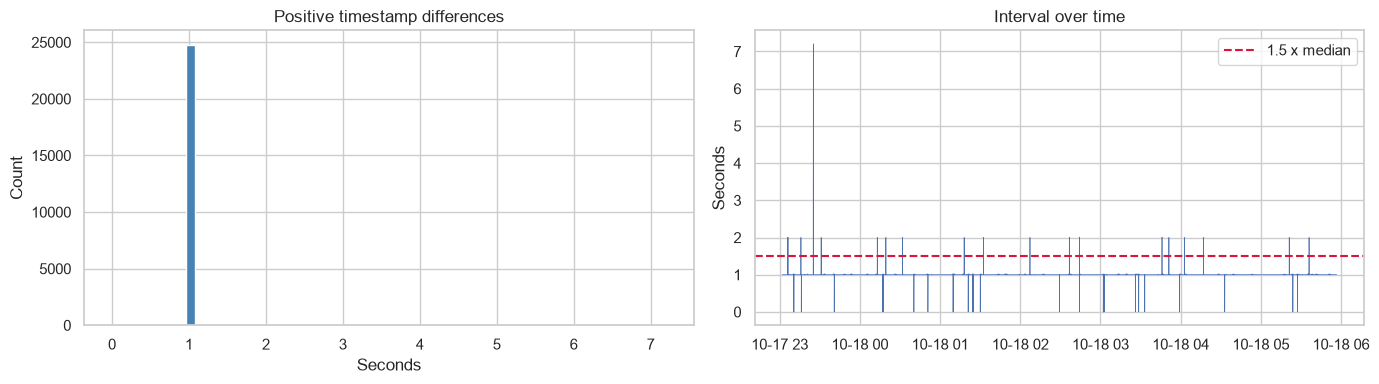

In [5]:
raw_dt = parsed_time.sort_values().diff().dt.total_seconds()
dt = df.index.to_series().diff().dt.total_seconds()
positive_dt = dt[dt > 0]
median_interval = positive_dt.median()
print("Raw timestamp differences (seconds; includes repeated timestamps):")
display(raw_dt.describe(percentiles=[.5, .9, .99]).to_frame("seconds"))
print("Unique-time positive intervals (seconds):")
display(positive_dt.describe(percentiles=[.5, .9, .99]).to_frame("seconds"))
print("Median observed interval:", median_interval, "seconds")
print(f"Unity configured interval from project notes: 0.25 s; observed median is {median_interval / 0.25:.1f}x that value. Verify historian/export cadence rather than assuming 0.25 s samples.")
print("Repeated-timestamp intervals in raw delta series:", int(raw_dt.eq(0).sum()))
gap_summary = []
for factor in (1.5, 2, 5, 10):
    selected = positive_dt[positive_dt > factor * median_interval]
    gap_summary.append({"multiple": factor, "threshold_s": factor * median_interval,
                        "count": len(selected), "elapsed_s": selected.sum()})
display(pd.DataFrame(gap_summary).set_index("multiple"))
gap_mask = dt > 1.5 * median_interval
gap_table = pd.DataFrame({"gap_seconds": dt[gap_mask]})
gap_table["estimated_missing_intervals"] = np.maximum(
    np.rint(gap_table["gap_seconds"] / median_interval) - 1, 0)
display(gap_table.sort_values("gap_seconds", ascending=False).head(15))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].hist(positive_dt, bins=60, color="steelblue")
axes[0].set(title="Positive timestamp differences", xlabel="Seconds", ylabel="Count")
axes[1].plot(df.index, dt, linewidth=.5)
axes[1].axhline(1.5 * median_interval, color="crimson", ls="--", label="1.5 x median")
axes[1].set(title="Interval over time", ylabel="Seconds")
axes[1].legend()
plt.tight_layout()
plt.show()

## C. Operating states, transitions, and segments

Running/stopped periods derive from `isMotorRunning`. Large gaps and state changes
start new segments, preventing rolling calculations and sequence candidates from
bridging discontinuities. Stopped time includes possible draining and cooldown; it
is not automatically an anomaly.

Operational state periods (gaps can split a period into multiple continuous segments):


,period_id,state,start,end,duration_s,observations,continuous_segments,median_speed,median_load
0,1,stopped,2026-10-17 23:01:54.524,2026-10-17 23:02:08.533,14.009,15,1,0.00,0.000000
1,2,running,2026-10-17 23:02:09.535,2026-10-17 23:56:16.647,3247.112,3236,7,0.45,14.972400
2,3,stopped,2026-10-17 23:56:17.647,2026-10-18 00:01:18.882,301.235,302,1,0.00,0.000002
3,4,running,2026-10-18 00:01:19.883,2026-10-18 00:55:27.455,3247.572,3244,4,0.45,15.385450
4,5,stopped,2026-10-18 00:55:28.456,2026-10-18 01:00:29.682,301.226,302,1,0.00,-0.000019
5,6,running,2026-10-18 01:00:30.682,2026-10-18 01:54:39.883,3249.201,3248,3,0.45,20.204314
6,7,stopped,2026-10-18 01:54:40.883,2026-10-18 01:59:42.109,301.226,302,1,0.00,-0.000001
7,8,running,2026-10-18 01:59:43.109,2026-10-18 02:53:46.129,3243.020,3238,4,0.75,5.185493
8,9,stopped,2026-10-18 02:53:47.130,2026-10-18 02:58:48.346,301.216,302,1,0.00,-0.000006
9,10,running,2026-10-18 02:58:49.347,2026-10-18 03:52:58.041,3248.694,3249,3,0.45,20.200439


Continuous state-consistent data segments, split at gaps:


,state,start,end,observations
segment_id,,,,
1,stopped,2026-10-17 23:01:54.524,2026-10-17 23:02:08.533,15
2,running,2026-10-17 23:02:09.535,2026-10-17 23:05:58.718,230
3,running,2026-10-17 23:06:00.718,2026-10-17 23:06:05.721,6
4,running,2026-10-17 23:06:07.721,2026-10-17 23:15:50.534,585
5,running,2026-10-17 23:15:52.534,2026-10-17 23:25:02.969,552
6,running,2026-10-17 23:25:10.174,2026-10-17 23:25:10.174,1
7,running,2026-10-17 23:25:12.236,2026-10-17 23:30:59.507,348
8,running,2026-10-17 23:31:01.507,2026-10-17 23:56:16.647,1514
9,stopped,2026-10-17 23:56:17.647,2026-10-18 00:01:18.882,302


State transitions: 15


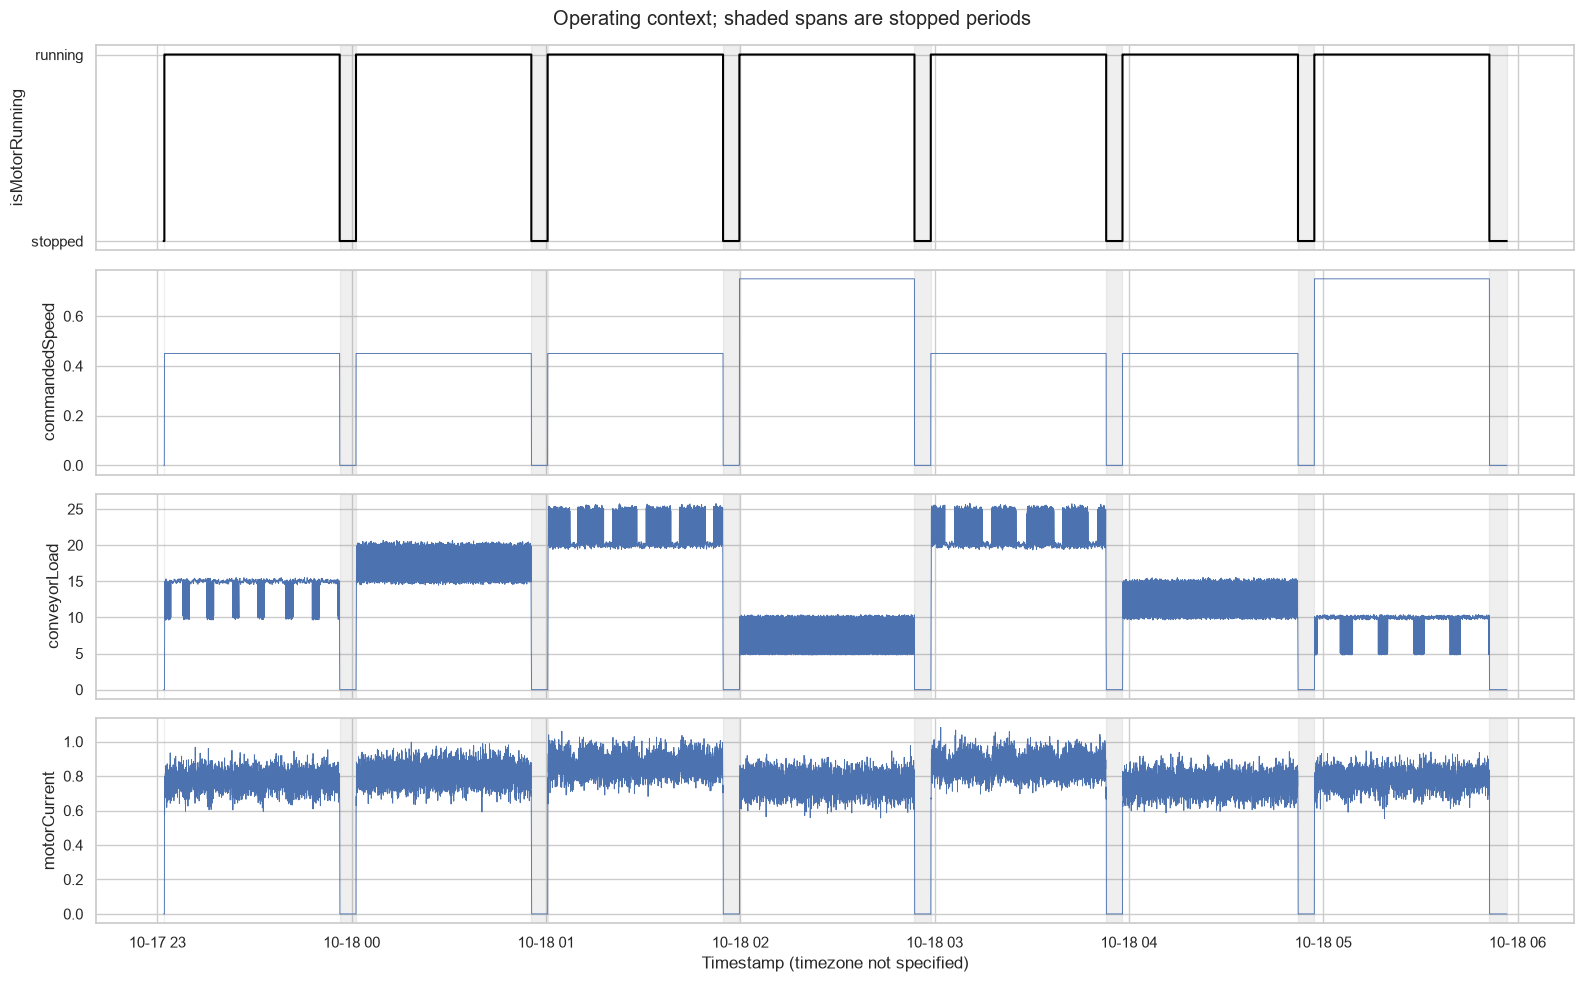

In [6]:
state = df["isMotorRunning"].where(df["isMotorRunning"].isin([0, 1]))
state_transition = state.ne(state.shift())
break_before = state_transition | gap_mask
# Analysis segments stop at gaps and state changes; operational periods stop only at state changes.
df["segment_id"] = break_before.cumsum().astype("int64")
df["state_period_id"] = state_transition.cumsum().astype("int64")
df["state"] = state.map({0: "stopped", 1: "running"})
period_rows = []
for pid, part in df.groupby("state_period_id", sort=True):
    s = part["state"].dropna()
    period_rows.append({
        "period_id": int(pid), "state": s.iloc[0] if len(s) else "unknown",
        "start": part.index[0], "end": part.index[-1],
        "duration_s": (part.index[-1] - part.index[0]).total_seconds(),
        "observations": len(part), "continuous_segments": part["segment_id"].nunique(),
        "median_speed": part["commandedSpeed"].median(),
        "median_load": part["conveyorLoad"].median(),
    })
periods = pd.DataFrame(period_rows)
continuous_segments = df.groupby("segment_id").agg(
    state=("state", "first"), start=("commandedSpeed", lambda x: x.index[0]),
    end=("commandedSpeed", lambda x: x.index[-1]), observations=("state", "size"))
print("Operational state periods (gaps can split a period into multiple continuous segments):")
display(periods)
print("Continuous state-consistent data segments, split at gaps:")
display(continuous_segments)
print("State transitions:", int(state_transition.sum() - state.isna().sum()))

fig, axes = plt.subplots(4, 1, figsize=(16, 10), sharex=True)
for ax, col in zip(axes, ["isMotorRunning", "commandedSpeed", "conveyorLoad", "motorCurrent"]):
    if col == "isMotorRunning":
        ax.step(df.index, df[col], where="post", color="black")
        ax.set_yticks([0, 1], labels=["stopped", "running"])
    else:
        ax.plot(df.index, df[col], linewidth=.65)
    ax.set_ylabel(col)
    for _, p in periods.iterrows():
        if p["state"] == "stopped":
            ax.axvspan(p["start"], p["end"], color="grey", alpha=.12)
axes[-1].set_xlabel("Timestamp (timezone not specified)")
fig.suptitle("Operating context; shaded spans are stopped periods")
plt.tight_layout()
plt.show()

,transition,from,to,speed_before,speed_after,current_before,current_after
0,2026-10-17 23:01:54.524,stopped,stopped,0.00,0.00,0.000000,0.000000
1,2026-10-17 23:02:09.535,stopped,running,0.00,0.45,0.000000,0.000000
2,2026-10-17 23:56:17.647,running,stopped,0.45,0.00,0.631180,0.631180
3,2026-10-18 00:01:19.883,stopped,running,0.00,0.45,0.000000,0.000000
4,2026-10-18 00:55:28.456,running,stopped,0.45,0.00,0.597360,0.557835
5,2026-10-18 01:00:30.682,stopped,running,0.00,0.45,0.000000,0.000000
6,2026-10-18 01:54:40.883,running,stopped,0.45,0.00,0.625130,0.641440
7,2026-10-18 01:59:43.109,stopped,running,0.00,0.75,0.000000,0.000000
8,2026-10-18 02:53:47.130,running,stopped,0.75,0.00,0.707035,0.760781
9,2026-10-18 02:58:49.347,stopped,running,0.00,0.45,0.000000,0.000000


Observed stopped periods and temperature changes (stopped can include drain/settling/cooldown):


,start,end,stopped_duration_s,roller_1_bearing_1_temp_change,roller_1_bearing_2_temp_change,roller_2_bearing_1_temp_change,roller_2_bearing_2_temp_change
0,2026-10-17 23:01:54.524,2026-10-17 23:02:08.533,14.009,0.000000,0.000000,0.000000,0.000000
1,2026-10-17 23:56:17.647,2026-10-18 00:01:18.882,301.235,-6.896669,-7.369761,-6.631750,-7.768730
2,2026-10-18 00:55:28.456,2026-10-18 01:00:29.682,301.226,-7.207659,-8.137260,-7.777348,-7.656950
3,2026-10-18 01:54:40.883,2026-10-18 01:59:42.109,301.226,-8.160580,-8.193670,-8.241529,-8.007540
4,2026-10-18 02:53:47.130,2026-10-18 02:58:48.346,301.216,-7.320528,-6.311050,-6.812101,-6.890091
5,2026-10-18 03:52:59.042,2026-10-18 03:58:00.260,301.218,-8.049980,-7.222870,-7.684938,-7.439060
6,2026-10-18 04:52:12.820,2026-10-18 04:57:14.589,301.769,-7.991819,-6.588610,-7.418941,-7.896820
7,2026-10-18 05:51:18.611,2026-10-18 05:56:42.189,323.578,-6.775429,-6.978750,-6.831360,-6.946951


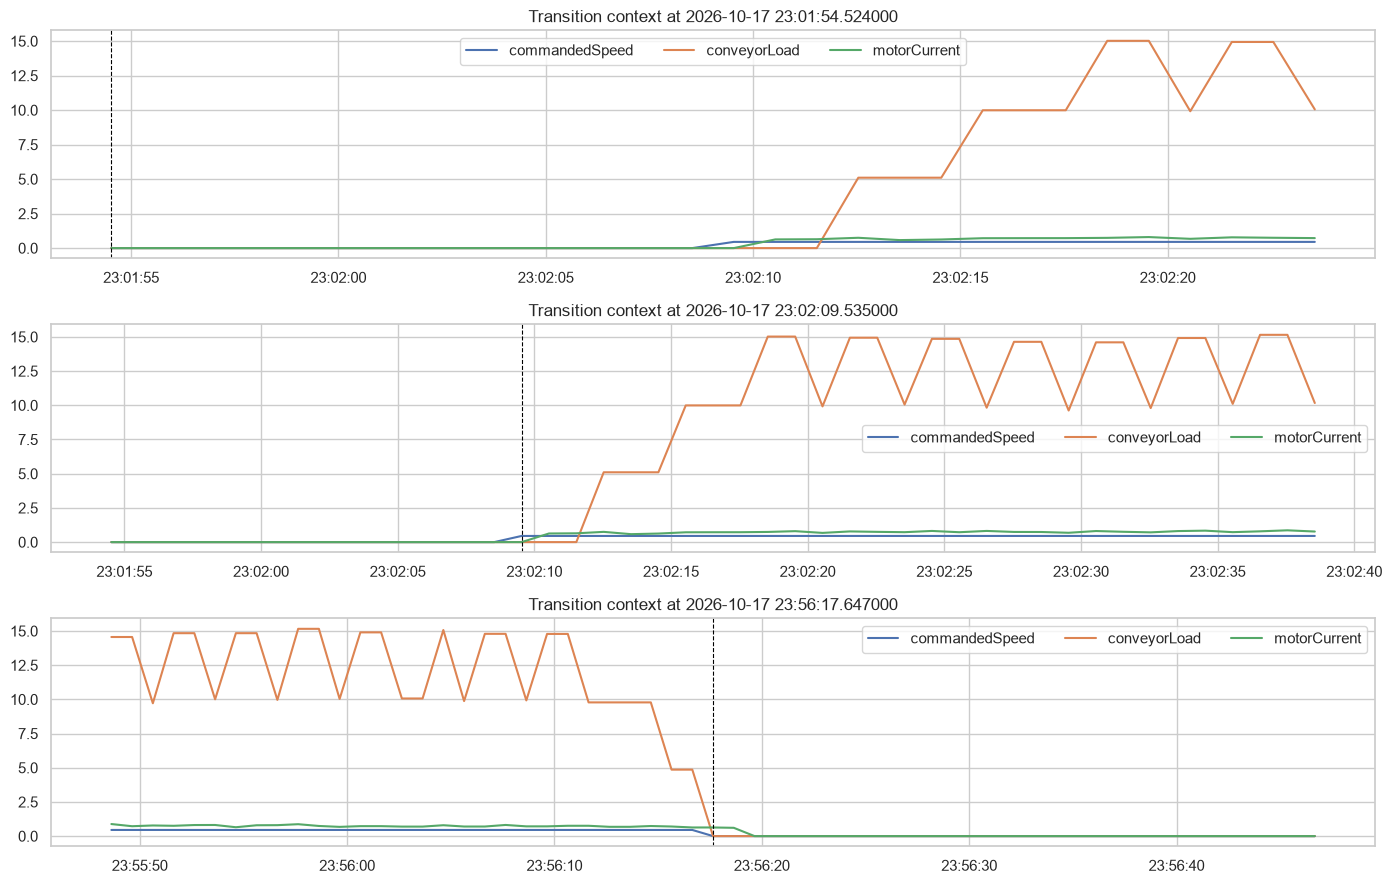

In [7]:
transition_times = df.index[state_transition]
transition_rows = []
for timestamp in transition_times:
    pos = df.index.get_indexer([timestamp])[0]
    before = df.iloc[max(0, pos - 1)]
    after = df.iloc[min(len(df) - 1, pos + 1)]
    transition_rows.append({"transition": timestamp, "from": before["state"],
                            "to": df.iloc[pos]["state"],
                            "speed_before": before["commandedSpeed"],
                            "speed_after": df.iloc[pos]["commandedSpeed"],
                            "current_before": before["motorCurrent"],
                            "current_after": df.iloc[pos]["motorCurrent"]})
display(pd.DataFrame(transition_rows))

stop_rows = []
for _, p in periods.loc[periods["state"].eq("stopped")].iterrows():
    sub = df.loc[p["start"]:p["end"]]
    row = {"start": p["start"], "end": p["end"], "stopped_duration_s": p["duration_s"]}
    for col in [c for c in EXPECTED if c.endswith("_temp") and c in df]:
        row[f"{col}_change"] = sub[col].iloc[-1] - sub[col].iloc[0]
    stop_rows.append(row)
print("Observed stopped periods and temperature changes (stopped can include drain/settling/cooldown):")
display(pd.DataFrame(stop_rows))

selected = list(transition_times[:3])
fig, axes = plt.subplots(len(selected), 1, figsize=(14, 3 * len(selected)), sharex=False)
for ax, timestamp in zip(np.atleast_1d(axes), selected):
    window = df.loc[timestamp - pd.Timedelta(seconds=30):timestamp + pd.Timedelta(seconds=30)]
    for col in ["commandedSpeed", "conveyorLoad", "motorCurrent"]:
        ax.plot(window.index, window[col], label=col)
    ax.axvline(timestamp, color="black", linestyle="--", linewidth=.8)
    ax.set_title(f"Transition context at {timestamp}")
    ax.legend(ncol=3)
plt.tight_layout()
plt.show()

,interval_count,median_s,mean_s,std_s,max_s,gaps_over_1.5x
state,,,,,,
running,22694,1.001,1.0015,0.0619,7.205,20
stopped,2143,1.001,1.0012,0.0022,1.018,0


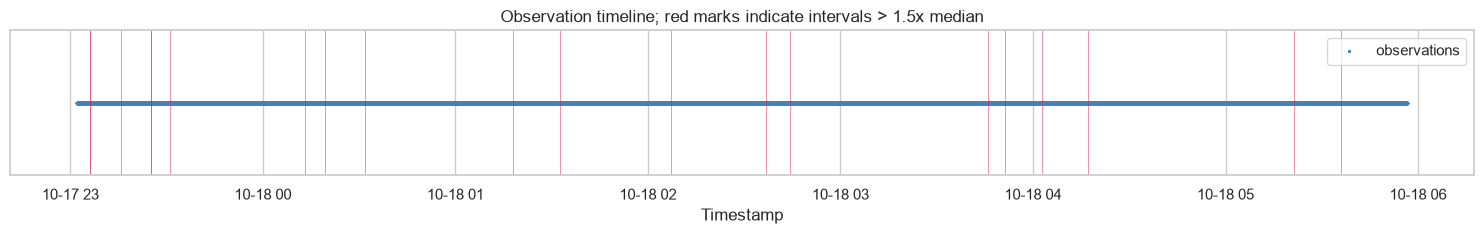

,longest_exact_repeat_observations,approx_seconds
tag,,
commandedSpeed,2835,2837.835
conveyorLoad,323,323.323
motorCurrent,322,322.322
roller_1_bearing_1_temp,22,22.022
roller_1_bearing_1_vibration,322,322.322
roller_1_bearing_2_temp,22,22.022
roller_1_bearing_2_vibration,322,322.322
roller_2_bearing_1_temp,22,22.022
roller_2_bearing_1_vibration,322,322.322


In [8]:
interval_state = state.eq(state.shift()) & state.notna()
cadence_rows = []
for value, label in [(1, "running"), (0, "stopped")]:
    deltas = dt.loc[interval_state & state.eq(value)].dropna()
    cadence_rows.append({"state": label, "interval_count": len(deltas),
                         "median_s": deltas.median(), "mean_s": deltas.mean(),
                         "std_s": deltas.std(), "max_s": deltas.max(),
                         "gaps_over_1.5x": int(deltas.gt(1.5 * median_interval).sum())})
display(pd.DataFrame(cadence_rows).set_index("state").round(4))

fig, ax = plt.subplots(figsize=(15, 2.5))
ax.scatter(df.index, np.zeros(len(df)), s=2, color="steelblue", label="observations")
for timestamp, gap in gap_table["gap_seconds"].items():
    ax.axvline(timestamp, color="crimson", alpha=.45, linewidth=.7)
ax.set(title="Observation timeline; red marks indicate intervals > 1.5x median",
       xlabel="Timestamp", yticks=[])
ax.legend()
plt.tight_layout()
plt.show()

# Longest exact repeated-value runs are calculated within continuous segments.
flatline_rows = []
for col in features:
    x = df[col]
    run_key = (x.ne(x.shift()) | df["segment_id"].ne(df["segment_id"].shift())).cumsum()
    lengths = x.notna().groupby(run_key).sum()
    candidates = lengths[lengths > 1]
    flatline_rows.append({"tag": col,
                          "longest_exact_repeat_observations": int(candidates.max()) if len(candidates) else 1,
                          "approx_seconds": (int(candidates.max()) if len(candidates) else 1) * median_interval})
display(pd.DataFrame(flatline_rows).set_index("tag"))

## D. Descriptive statistics

Quantiles and spread are reported overall and by state. Pandas reports Fisher excess
kurtosis (normal distribution = 0). Pooled statistics can conceal state-dependent
behaviour and should not be treated as alarm limits.

In [9]:
groups_by_state = {"all": df, "running": df.loc[state.eq(1)], "stopped": df.loc[state.eq(0)]}
stats = {}
for label, subset in groups_by_state.items():
    x = subset[features]
    tab = x.describe(percentiles=[.01, .05, .25, .50, .75, .95, .99]).T
    tab["variance"], tab["IQR"] = x.var(), x.quantile(.75) - x.quantile(.25)
    tab["skew"], tab["kurtosis_fisher_excess"] = x.skew(), x.kurt()
    stats[label] = tab
display(stats["all"].round(4))
display(pd.concat({k: v[["count", "mean", "50%", "std"]]
                   for k, v in stats.items() if k != "all"}, axis=1).round(4))

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,variance,IQR,skew,kurtosis_fisher_excess
commandedSpeed,24852.0,0.4893,0.1986,0.0000,0.0000,0.0000,0.4500,0.4500,0.7500,0.7500,0.7500,0.7500,0.0394,0.3000,-0.7089,0.9639
conveyorLoad,24852.0,13.6684,6.9340,-0.0001,-0.0001,-0.0000,9.9174,14.8939,19.8999,24.9900,25.3315,25.8095,48.0810,9.9824,-0.2762,-0.6067
motorCurrent,24852.0,0.7314,0.2353,0.0000,0.0000,0.0000,0.7342,0.7904,0.8435,0.9203,0.9713,1.0822,0.0554,0.1094,-2.4944,5.1482
roller_1_bearing_1_temp,24852.0,35.7139,2.2459,0.0000,29.2066,30.7788,35.4473,36.2984,37.0529,37.7737,38.0760,38.6862,5.0441,1.6056,-3.8921,42.2119
roller_1_bearing_1_vibration,24852.0,0.8851,0.3063,0.0000,0.0000,0.0000,0.8329,0.9422,1.0481,1.2175,1.3516,1.6481,0.0938,0.2152,-1.8534,3.3364
roller_1_bearing_2_temp,24852.0,35.7157,2.2429,0.0000,29.2910,30.7536,35.4276,36.3088,37.0523,37.7637,38.0667,38.7459,5.0304,1.6246,-3.9050,42.4571
roller_1_bearing_2_vibration,24852.0,0.8857,0.3073,0.0000,0.0000,0.0000,0.8337,0.9404,1.0499,1.2249,1.3607,1.7074,0.0944,0.2162,-1.8286,3.2905
roller_2_bearing_1_temp,24852.0,35.7142,2.2473,0.0000,29.2006,30.7462,35.4391,36.3073,37.0576,37.7711,38.0662,39.0066,5.0501,1.6184,-3.8910,42.1296
roller_2_bearing_1_vibration,24852.0,0.8851,0.3065,0.0000,0.0000,0.0000,0.8349,0.9420,1.0501,1.2209,1.3542,1.7182,0.0940,0.2152,-1.8498,3.3222
roller_2_bearing_2_temp,24852.0,35.7129,2.2464,0.0000,29.2709,30.7593,35.4391,36.3061,37.0525,37.7581,38.0526,38.6730,5.0461,1.6134,-3.8956,42.1986


running                           stopped  \
                                count     mean      50%     std   count   
commandedSpeed                22701.0   0.5356   0.4500  0.1355  2151.0   
conveyorLoad                  22701.0  14.9624  14.9802  5.7692  2151.0   
motorCurrent                  22701.0   0.8004   0.7990  0.0741  2151.0   
roller_1_bearing_1_temp       22701.0  36.0469  36.4130  1.7571  2151.0   
roller_1_bearing_1_vibration  22701.0   0.9686   0.9592  0.1478  2151.0   
roller_1_bearing_2_temp       22701.0  36.0480  36.4147  1.7536  2151.0   
roller_1_bearing_2_vibration  22701.0   0.9692   0.9576  0.1497  2151.0   
roller_2_bearing_1_temp       22701.0  36.0484  36.4167  1.7556  2151.0   
roller_2_bearing_1_vibration  22701.0   0.9686   0.9583  0.1483  2151.0   
roller_2_bearing_2_temp       22701.0  36.0463  36.4161  1.7570  2151.0   
roller_2_bearing_2_vibration  22701.0   0.9681   0.9590  0.1482  2151.0   

                                                        
                                 mean      50%     std  
commandedSpeed                 0.0003   0.0000  0.0162  
conveyorLoad                   0.0117  -0.0000  0.2422  
motorCurrent                   0.0039   0.0000  0.0507  
roller_1_bearing_1_temp       32.1991  32.1111  3.4891  
roller_1_bearing_1_vibration   0.0044   0.0000  0.0655  
roller_1_bearing_2_temp       32.2092  32.1213  3.4942  
roller_1_bearing_2_vibration   0.0042   0.0000  0.0623  
roller_2_bearing_1_temp       32.1875  32.0807  3.4943  
roller_2_bearing_1_vibration   0.0044   0.0000  0.0649  
roller_2_bearing_2_temp       32.1944  32.0745  3.4892  
roller_2_bearing_2_vibration   0.0050   0.0000  0.0667

## E. Distribution and outlier review

IQR fences and robust MAD scores identify candidates for inspection, never automatic
deletion. State-specific distributions help distinguish unusual readings from
operating-state effects.

,IQR_low,IQR_high,outside_IQR,MAD,abs_robust_z_gt_6
tag,,,,,
commandedSpeed,-2.980232e-08,1.200000,0,0.000000,0
conveyorLoad,-5.056180e+00,34.873500,0,4.987030,0
motorCurrent,5.701290e-01,1.007597,2204,0.054616,2149
roller_1_bearing_1_temp,3.303896e+01,39.461274,2945,0.789936,270
roller_1_bearing_1_vibration,5.101782e-01,1.370787,2343,0.107679,0
roller_1_bearing_2_temp,3.299071e+01,39.489199,2911,0.795195,234
roller_1_bearing_2_vibration,5.093500e-01,1.374222,2352,0.108164,0
roller_2_bearing_1_temp,3.301150e+01,39.485225,2919,0.793547,264
roller_2_bearing_1_vibration,5.120896e-01,1.372881,2353,0.107510,0


Review candidates in context; statistical fences do not establish sensor corruption or faults.


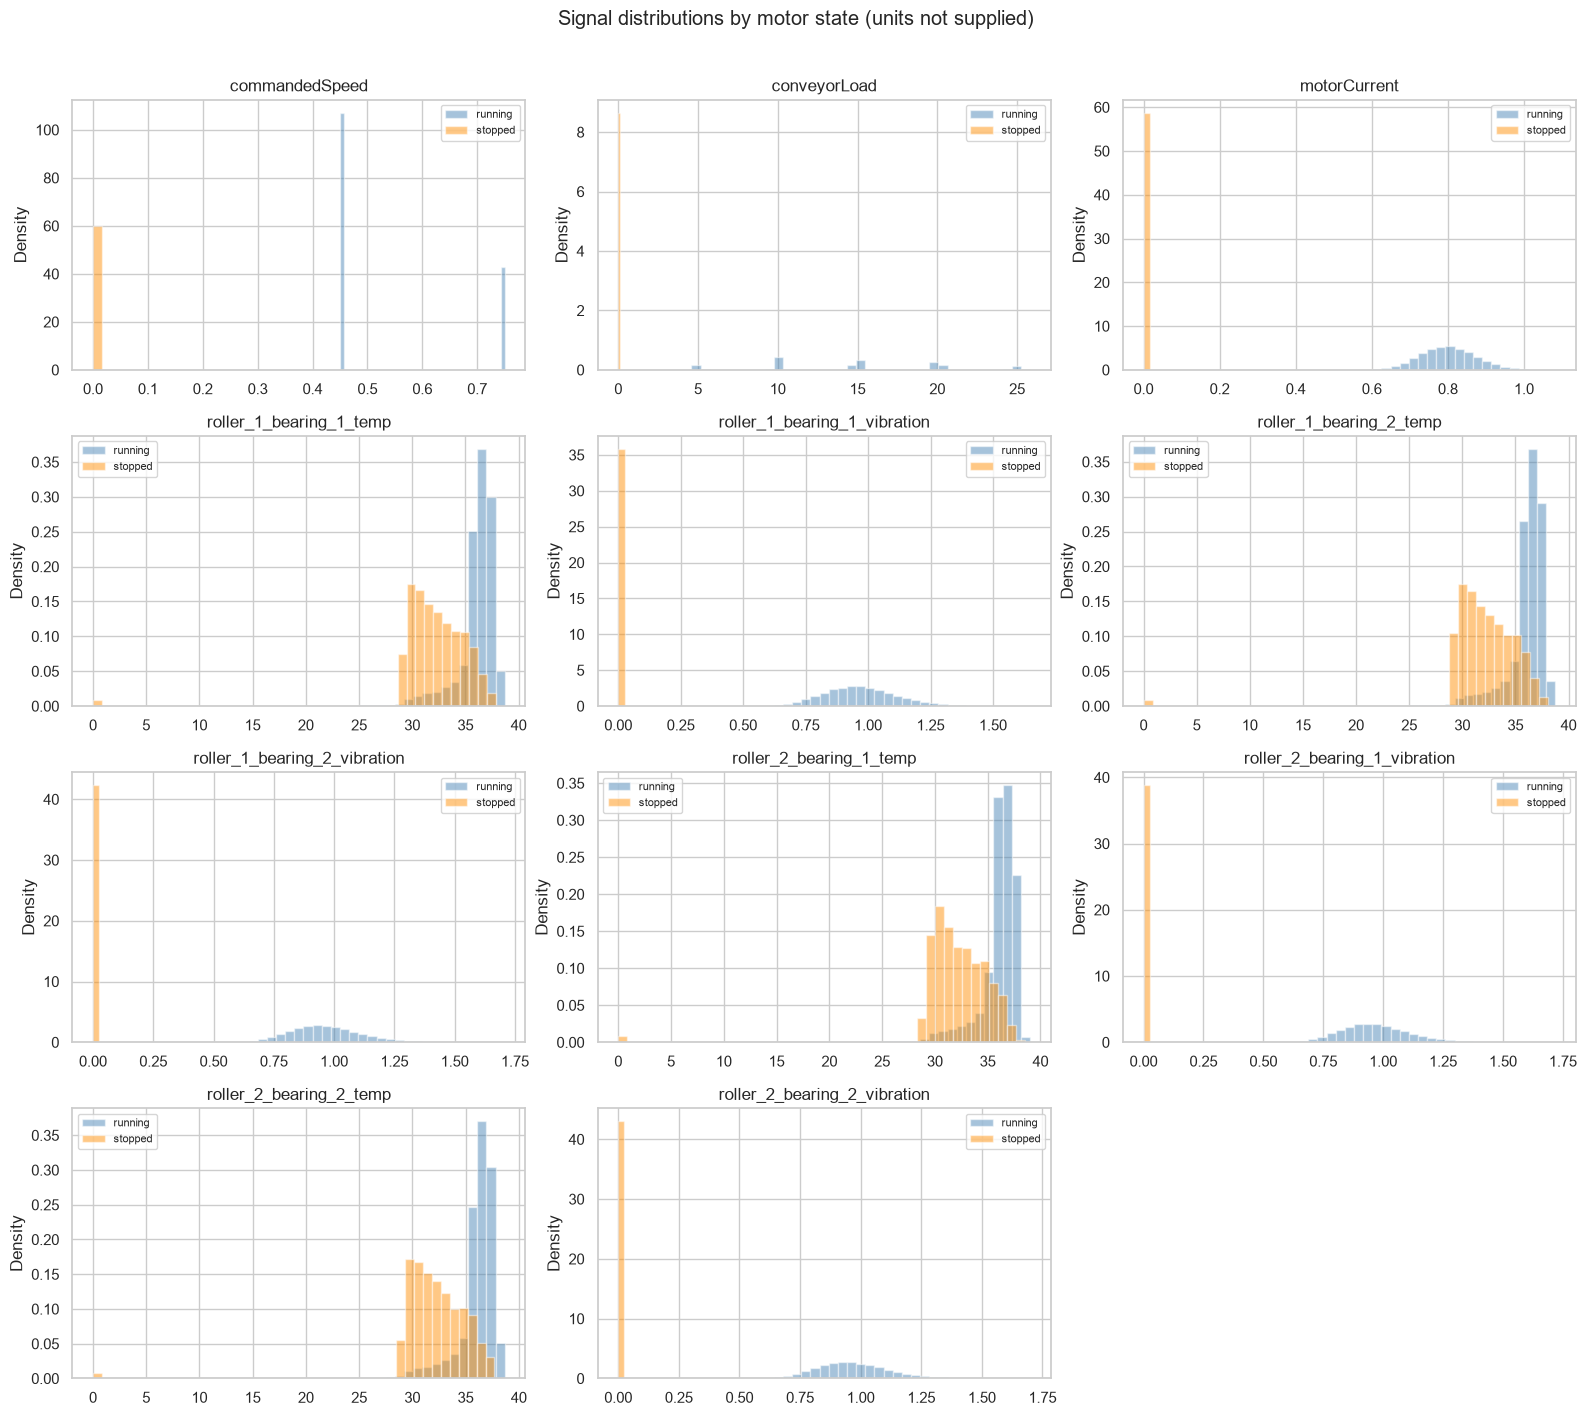

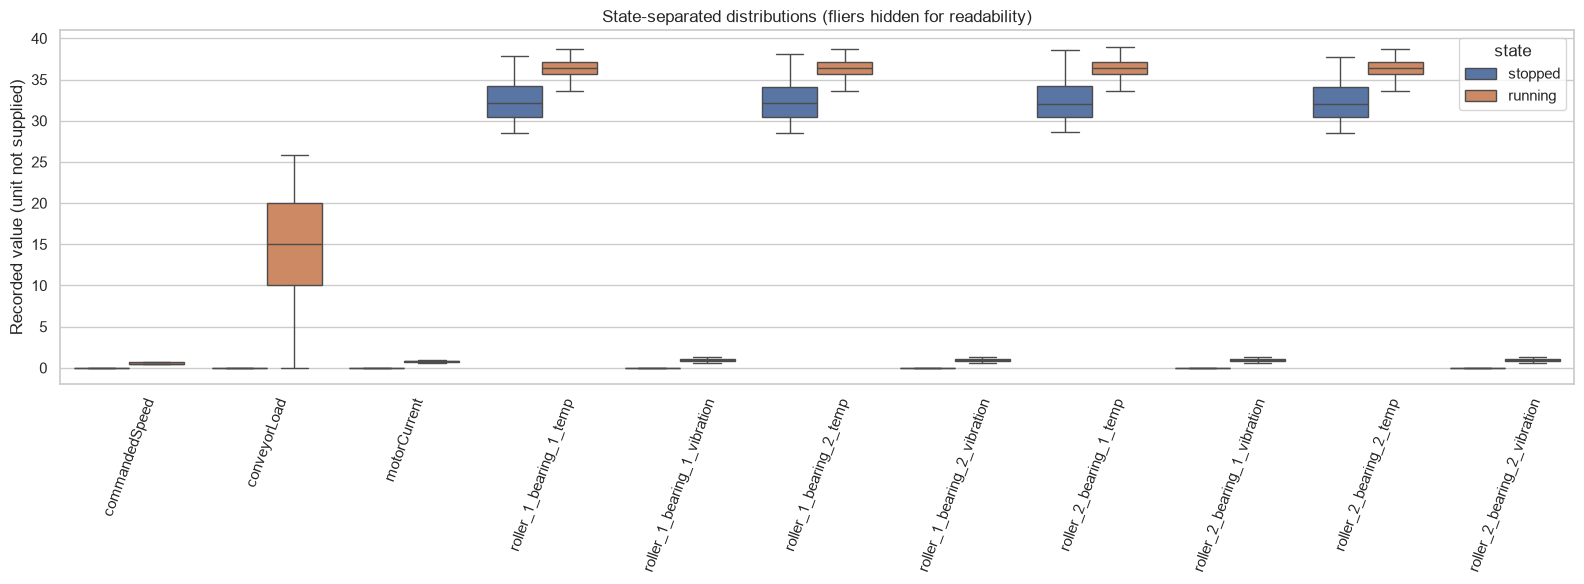

In [10]:
outlier_rows = []
for col in features:
    x = df[col].dropna()
    if x.empty:
        continue
    q1, q3 = x.quantile([.25, .75])
    iqr, med = q3 - q1, x.median()
    mad = (x - med).abs().median()
    rz = .6745 * (x - med) / mad if mad > 0 else pd.Series(np.nan, index=x.index)
    outlier_rows.append({
        "tag": col, "IQR_low": q1 - 1.5 * iqr, "IQR_high": q3 + 1.5 * iqr,
        "outside_IQR": int(((x < q1 - 1.5 * iqr) | (x > q3 + 1.5 * iqr)).sum()),
        "MAD": mad, "abs_robust_z_gt_6": int(rz.abs().gt(6).sum()),
    })
outliers = pd.DataFrame(outlier_rows).set_index("tag")
display(outliers)
print("Review candidates in context; statistical fences do not establish sensor corruption or faults.")

fig, axes = plt.subplots(4, 3, figsize=(16, 14))
for ax, col in zip(axes.flat, features):
    for val, label, color in [(1, "running", "steelblue"), (0, "stopped", "darkorange")]:
        x = df.loc[state.eq(val), col].dropna()
        if len(x):
            ax.hist(x, bins=45, alpha=.48, density=True, label=label, color=color)
    ax.set_title(col)
    ax.set_ylabel("Density")
    ax.legend(fontsize=8)
for ax in axes.flat[len(features):]:
    ax.set_visible(False)
fig.suptitle("Signal distributions by motor state (units not supplied)", y=1.01)
plt.tight_layout()
plt.show()

long_state = df[features + ["state"]].melt(
    id_vars="state", var_name="tag", value_name="value").dropna()
fig, ax = plt.subplots(figsize=(16, 6))
sns.boxplot(data=long_state, x="tag", y="value", hue="state",
            showfliers=False, ax=ax)
ax.set(title="State-separated distributions (fliers hidden for readability)",
       xlabel="", ylabel="Recorded value (unit not supplied)")
ax.tick_params(axis="x", rotation=70)
plt.tight_layout()
plt.show()

### Outlier investigation categories

IQR/MAD flags are not sufficient evidence to assign a sensor reading to a fault or corruption category. Use the following review rubric; until engineering limits and cross-sensor/event evidence are available, flagged points remain **uncertain** rather than being silently labelled or removed.

| Review category | Evidence needed | Status in this EDA |
|---|---|---|
| Likely invalid / data corruption | Impossible engineering range, parse/infinity error, or historian/PLC evidence of a bad value | No physical limits supplied; investigate flagged timestamps before assigning |
| Unusual but potentially valid | Extreme value within verified limits with coherent neighbouring sensors/state | Must be checked against bearing/current/load context |
| Explainable by operating state | Timing and direction align with startup, shutdown, drain, stopped, or cooldown behaviour | State context is plotted; no event is automatically called a fault |
| Uncertain | Statistical flag without decisive physical or event evidence | Default category for IQR/MAD-only candidates |


## F. Time-series trends and rolling statistics

All tags use parsed timestamps. Separate segment plotting prevents lines from
crossing a state change or large gap. Rolling summaries are computed within those
segments; they describe local behaviour, not ground-truth fault labels.

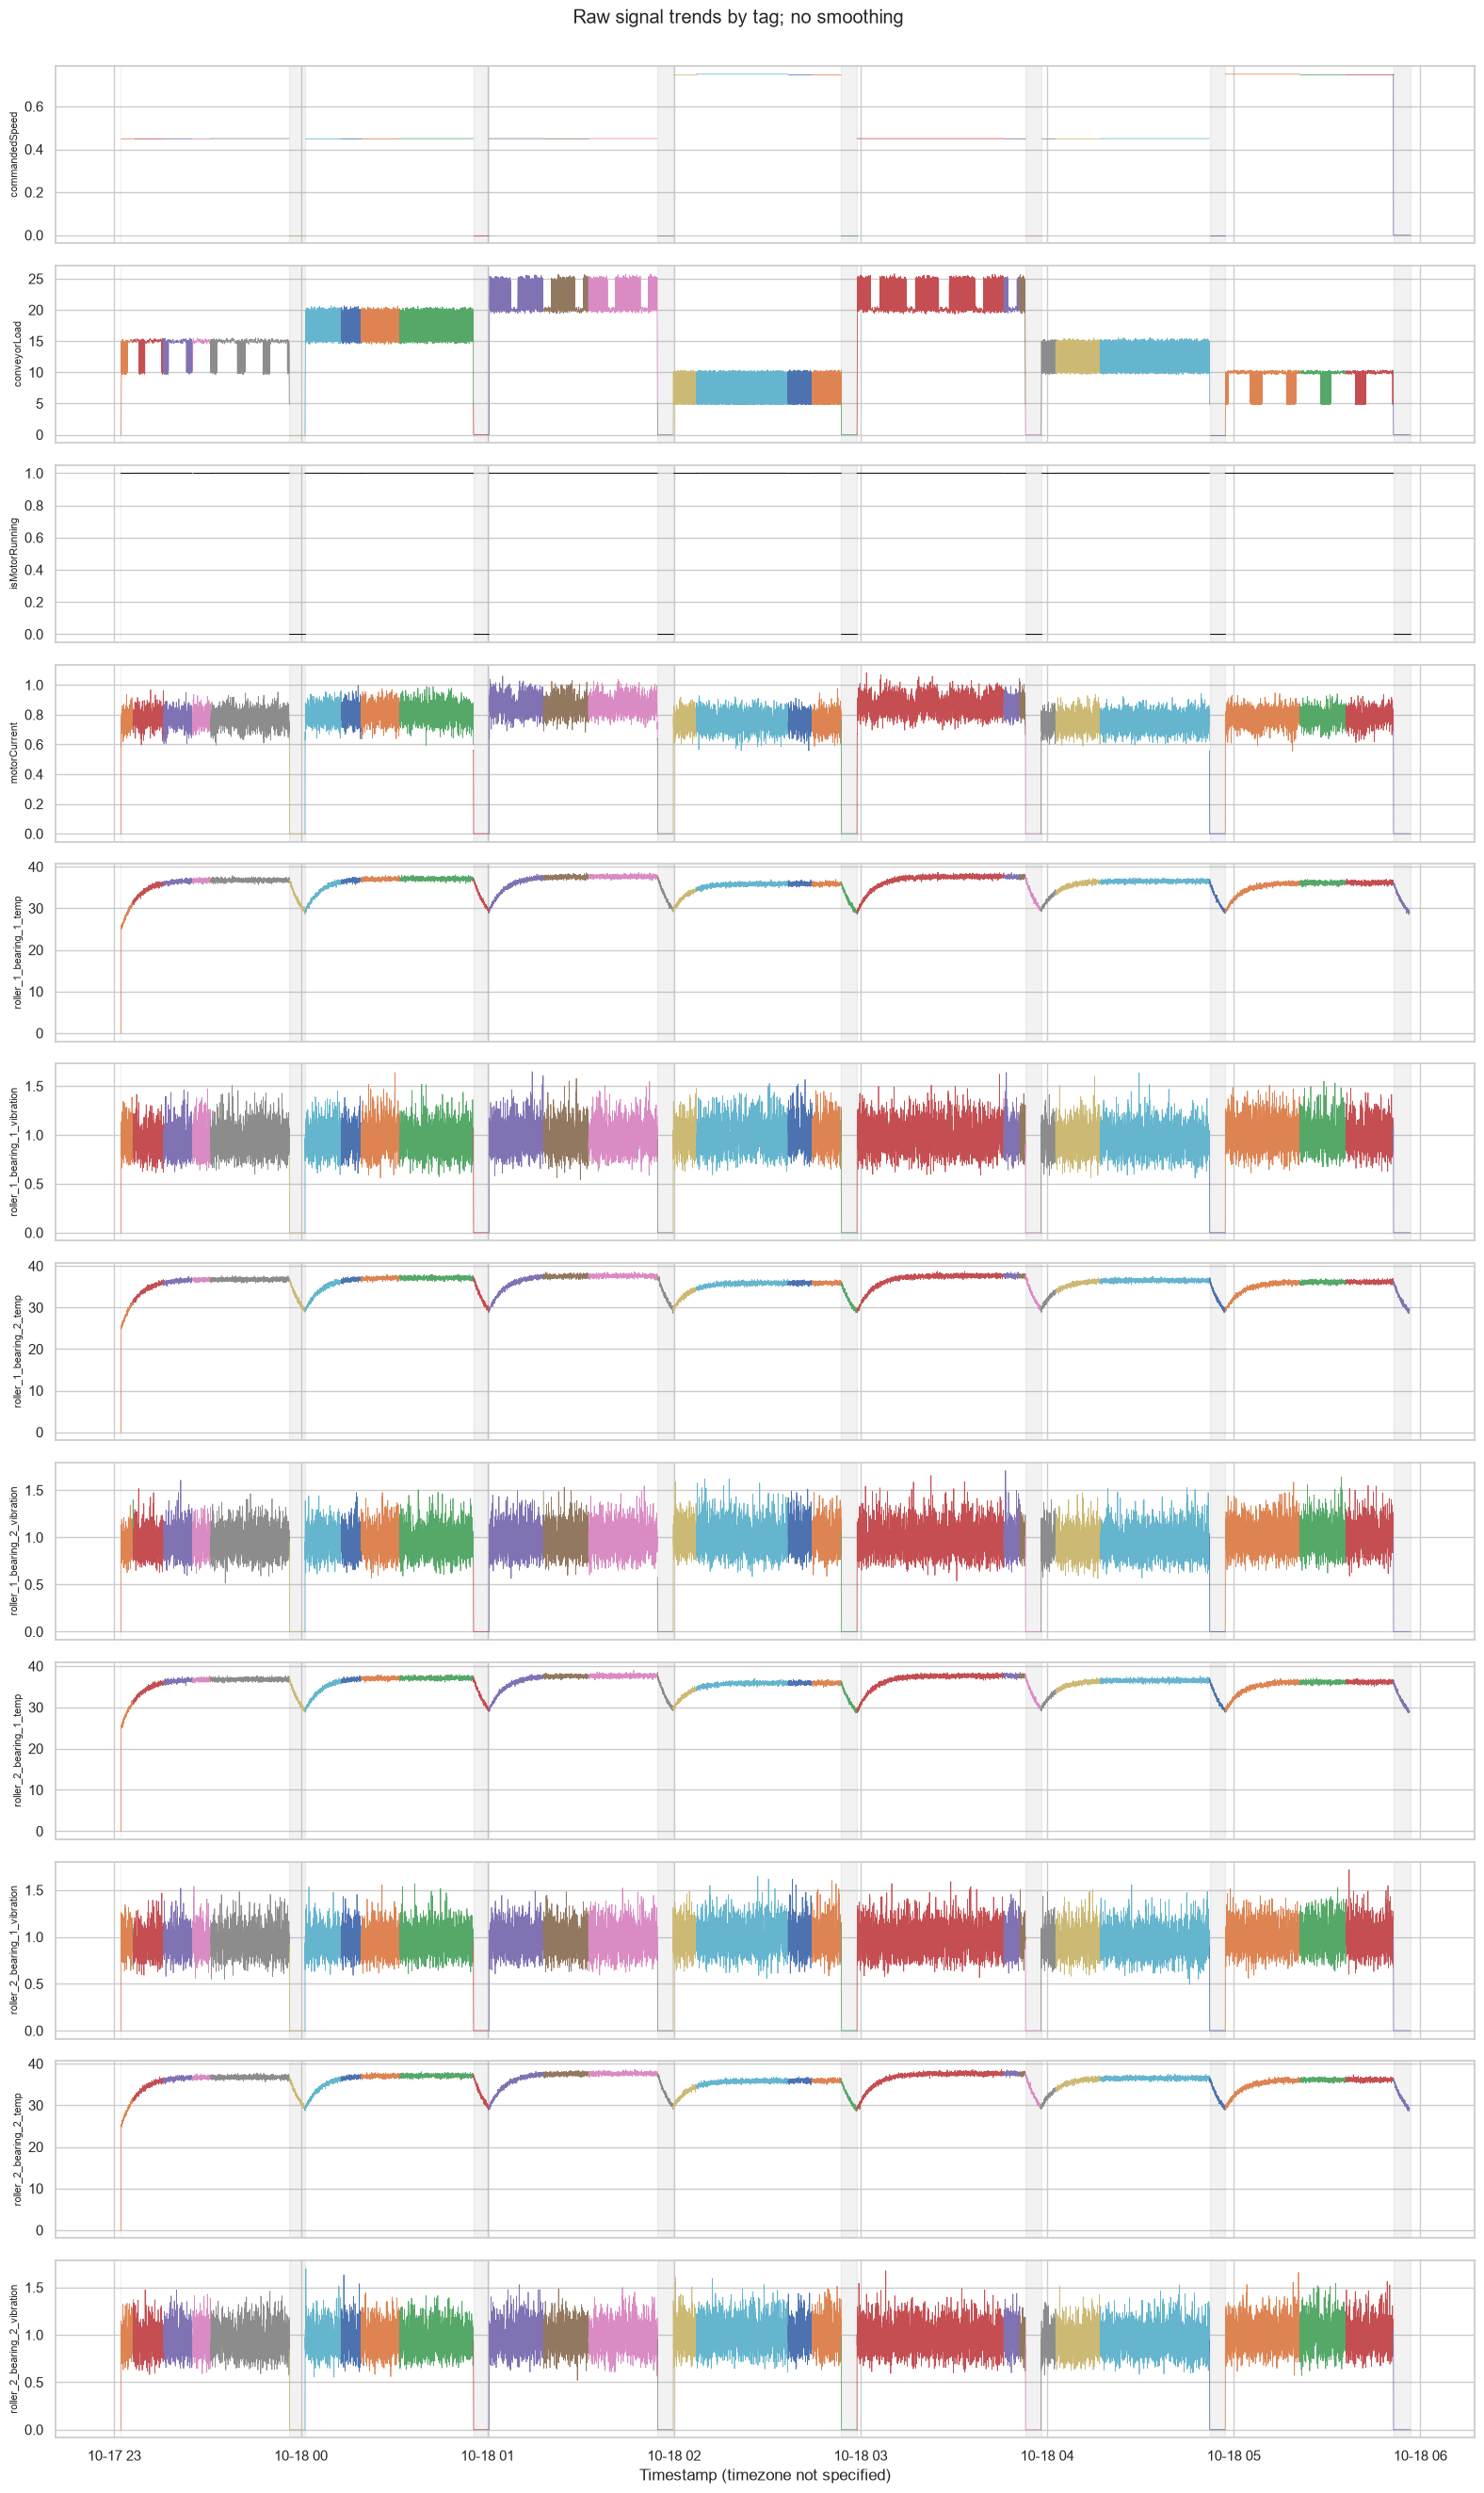

Window: 60 observations (~60.1 seconds).


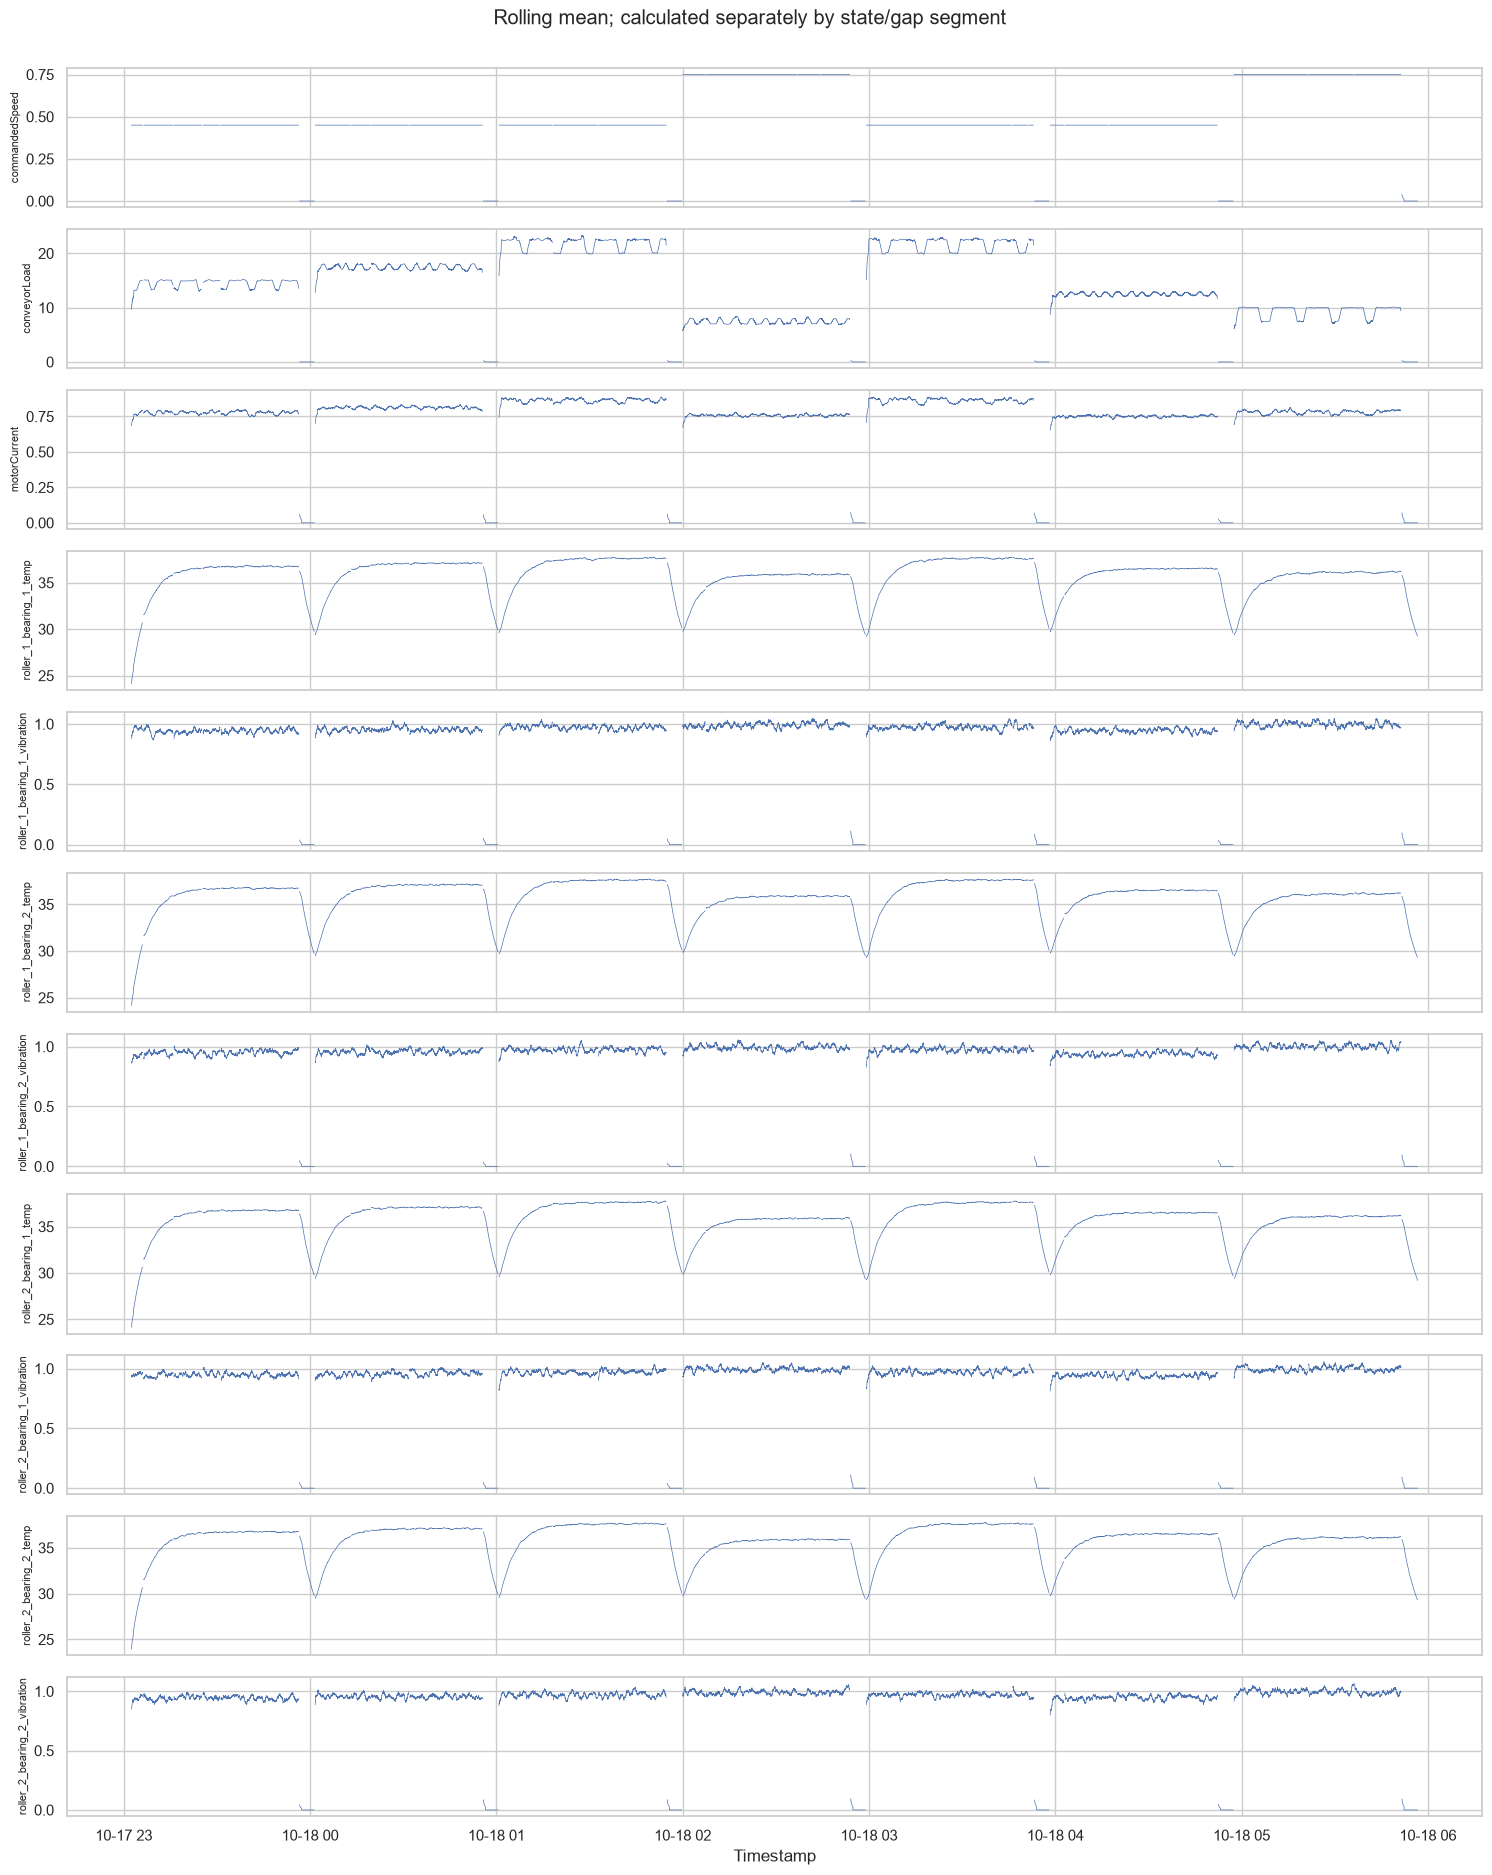

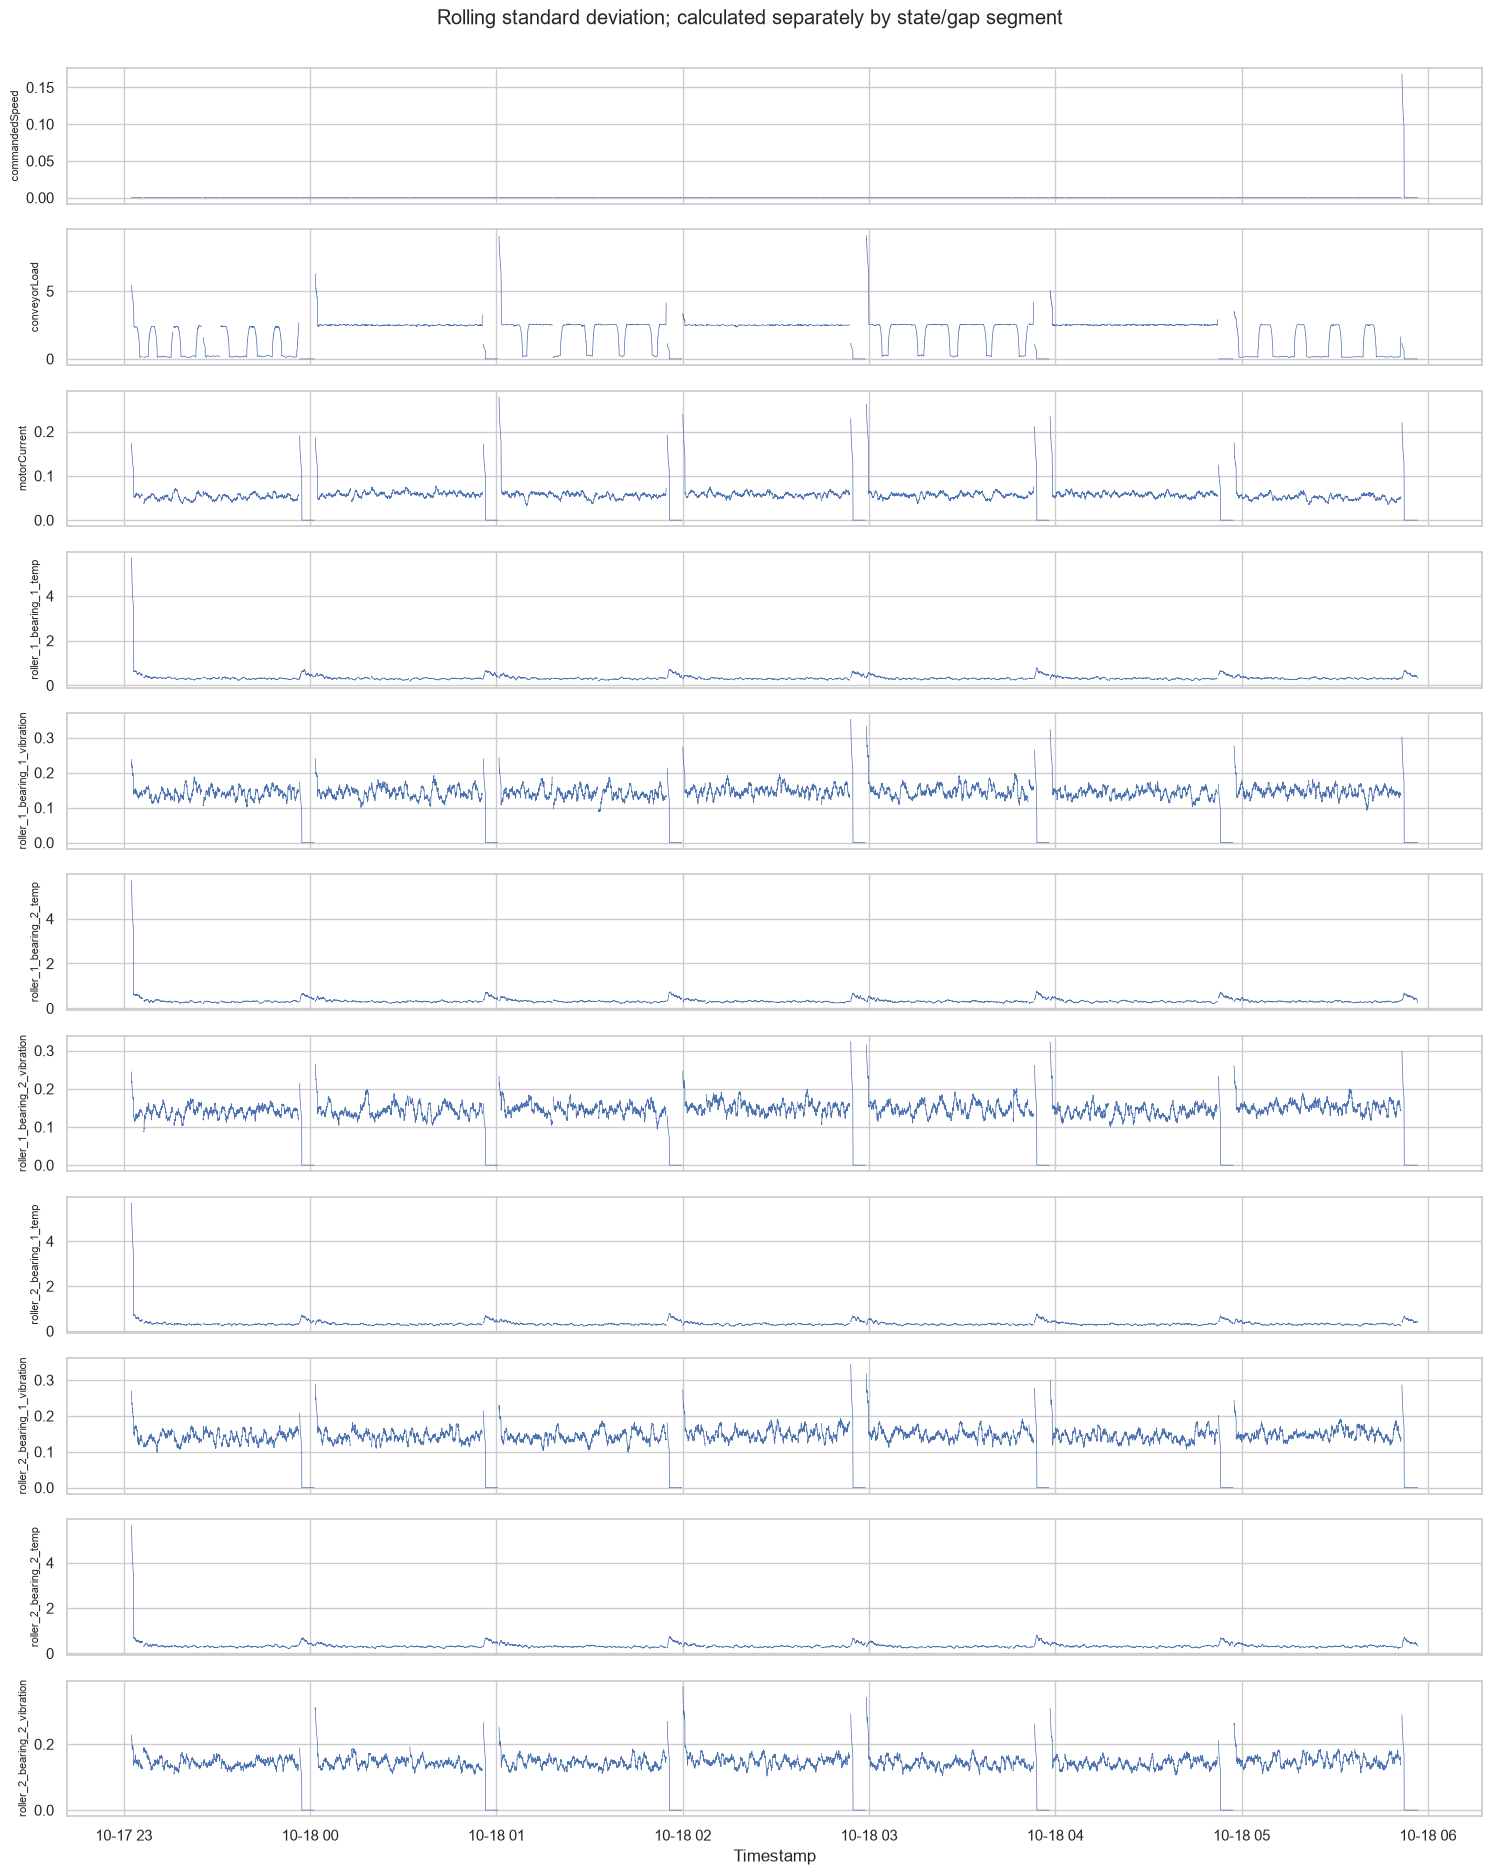

In [11]:
tags = [c for c in EXPECTED if c in df]
fig, axes = plt.subplots(len(tags), 1, figsize=(16, 2.2 * len(tags)), sharex=True)
for ax, col in zip(axes, tags):
    for _, part in df.groupby("segment_id", sort=True):
        if col == "isMotorRunning":
            ax.step(part.index, part[col], where="post", linewidth=.65, color="black")
        else:
            ax.plot(part.index, part[col], linewidth=.55)
    ax.set_ylabel(col, fontsize=8)
    for _, p in periods.iterrows():
        if p["state"] == "stopped":
            ax.axvspan(p["start"], p["end"], color="grey", alpha=.10)
axes[-1].set_xlabel("Timestamp (timezone not specified)")
fig.suptitle("Raw signal trends by tag; no smoothing", y=1.002)
plt.tight_layout()
plt.show()

window_seconds = 60
window_obs = max(3, int(round(window_seconds / median_interval)))
roll_mean = df[features].groupby(df["segment_id"]).transform(
    lambda s: s.rolling(window_obs, min_periods=max(2, window_obs // 3)).mean())
roll_std = df[features].groupby(df["segment_id"]).transform(
    lambda s: s.rolling(window_obs, min_periods=max(2, window_obs // 3)).std())
print(f"Window: {window_obs} observations (~{window_obs * median_interval:.1f} seconds).")
for vals, title in [(roll_mean, "Rolling mean"), (roll_std, "Rolling standard deviation")]:
    fig, axes = plt.subplots(len(features), 1, figsize=(15, 1.7 * len(features)), sharex=True)
    for ax, col in zip(axes, features):
        ax.plot(df.index, vals[col], linewidth=.5)
        ax.set_ylabel(col, fontsize=8)
    fig.suptitle(f"{title}; calculated separately by state/gap segment", y=1.002)
    axes[-1].set_xlabel("Timestamp")
    plt.tight_layout()
    plt.show()

## G. Autocorrelation, trends, and first differences

Autocorrelation is inspected within the longest uninterrupted running segment;
lags are observations, not guaranteed seconds. First-difference rates do not cross
segment boundaries. No ADF test is run: stationarity would not establish normal
operation, and no specific test-dependent decision is needed for this first EDA.

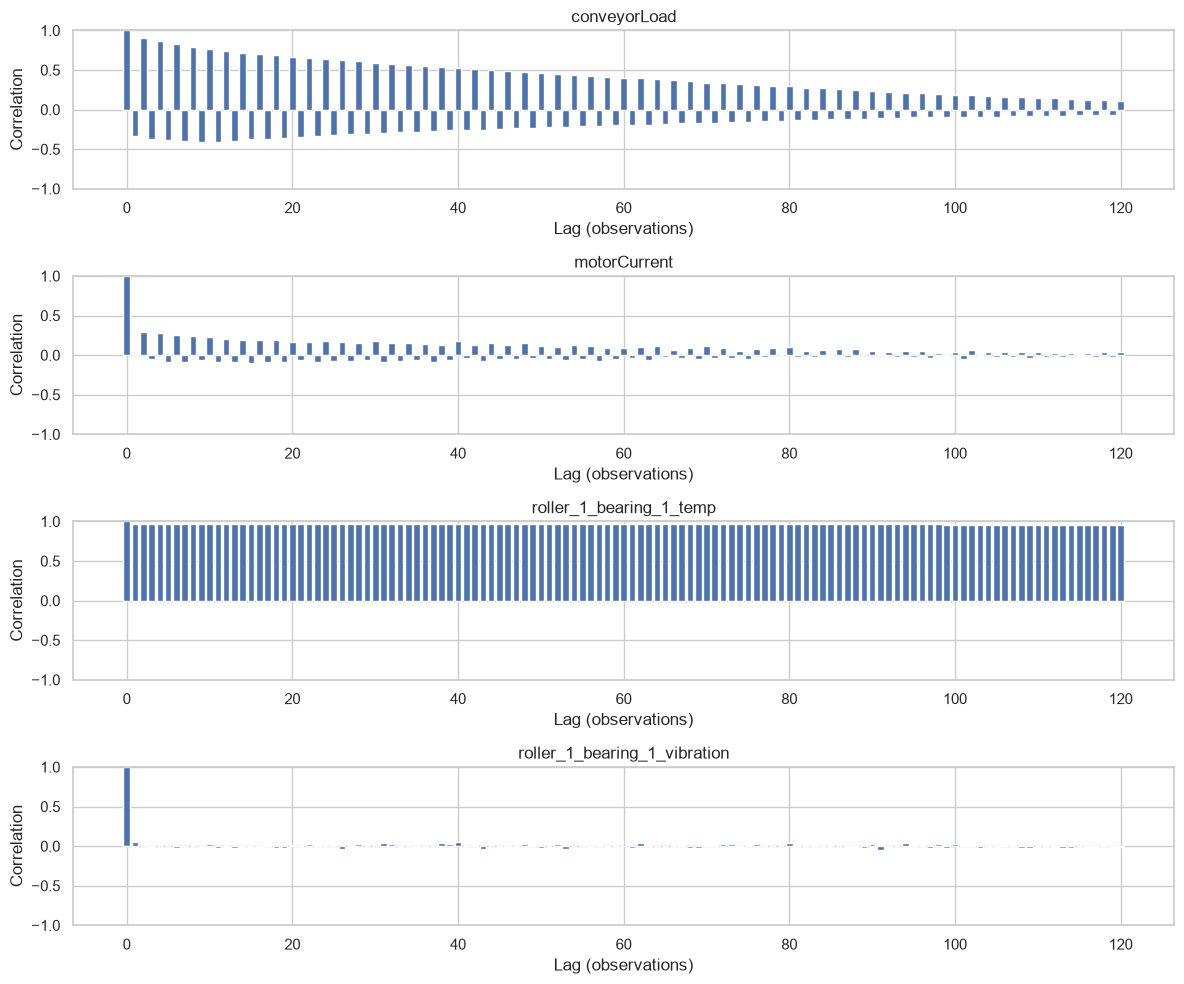

ACF segment: 2026-10-18 02:58:49.347000 to 2026-10-18 03:46:01.194000 | observations: 2835


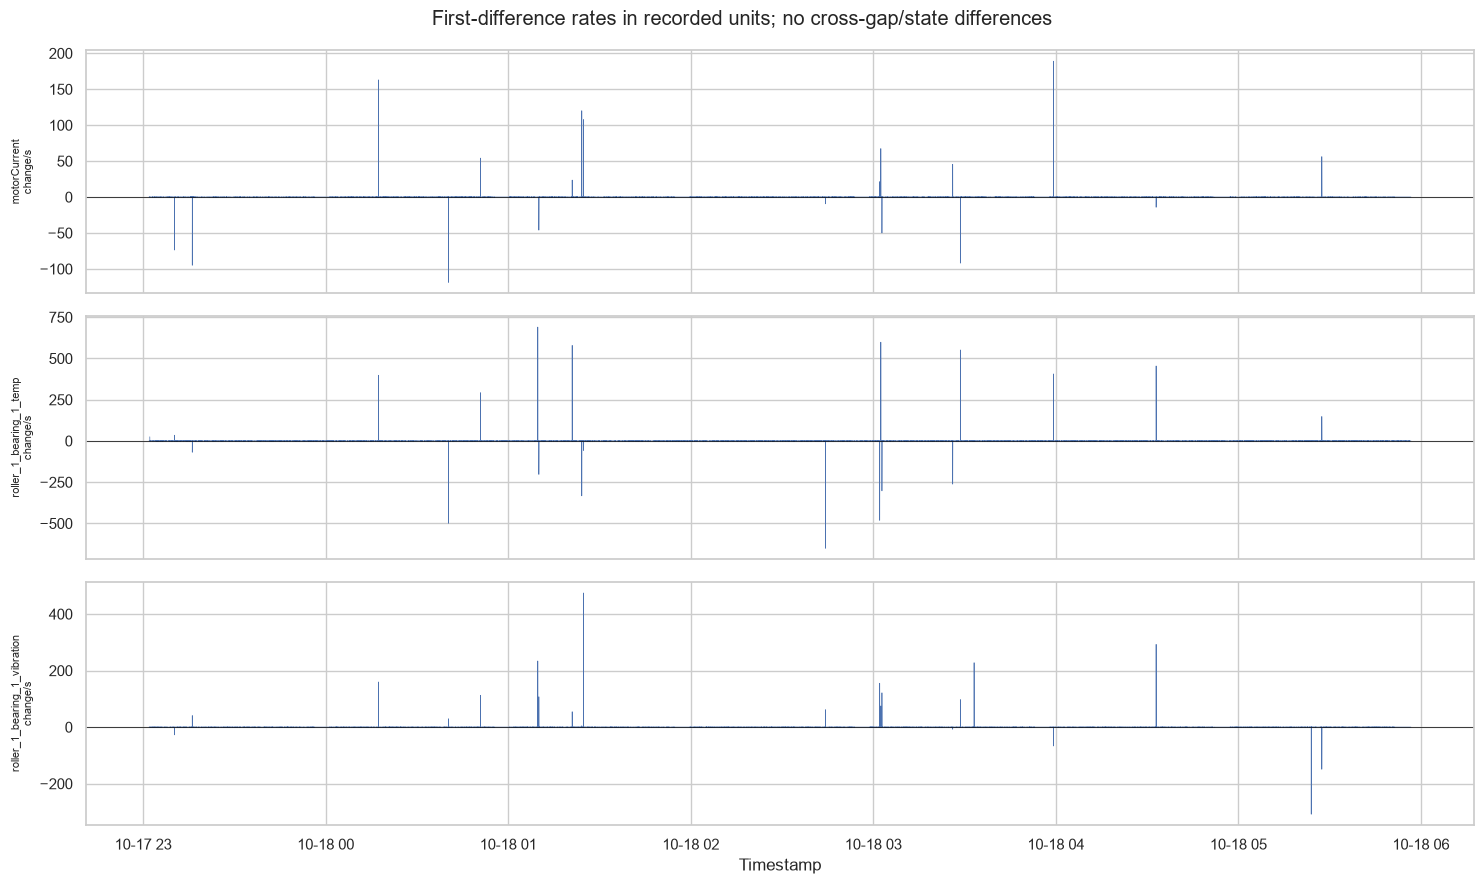

In [12]:
running_rows = df.loc[state.eq(1)]
running_parts = [p for _, p in running_rows.groupby(running_rows["segment_id"]) if len(p)]
if running_parts:
    acf_part = max(running_parts, key=len)
    acf_tags = [c for c in ["conveyorLoad", "motorCurrent",
                            "roller_1_bearing_1_temp",
                            "roller_1_bearing_1_vibration"] if c in df]
    max_lag = min(120, max(1, len(acf_part) // 4))
    fig, axes = plt.subplots(len(acf_tags), 1, figsize=(12, 2.5 * len(acf_tags)))
    for ax, col in zip(np.atleast_1d(axes), acf_tags):
        x = acf_part[col].dropna().to_numpy(dtype=float)
        vals = [1.0] + [
            np.corrcoef(x[:-lag], x[lag:])[0, 1]
            if len(x) > lag and np.std(x[:-lag]) and np.std(x[lag:]) else np.nan
            for lag in range(1, max_lag + 1)]
        ax.bar(np.arange(len(vals)), vals, width=.8)
        ax.set(title=col, xlabel="Lag (observations)", ylabel="Correlation", ylim=(-1, 1))
    plt.tight_layout()
    plt.show()
    print("ACF segment:", acf_part.index[0], "to", acf_part.index[-1],
          "| observations:", len(acf_part))

rate = df[features].groupby(df["segment_id"]).diff().div(dt.replace(0, np.nan), axis=0)
change_tags = [c for c in ["motorCurrent", "roller_1_bearing_1_temp",
                           "roller_1_bearing_1_vibration"] if c in features]
fig, axes = plt.subplots(len(change_tags), 1, figsize=(15, 3 * len(change_tags)), sharex=True)
for ax, col in zip(np.atleast_1d(axes), change_tags):
    ax.plot(df.index, rate[col], linewidth=.5)
    ax.axhline(0, color="black", linewidth=.5)
    ax.set_ylabel(f"{col}\nchange/s", fontsize=8)
axes[-1].set_xlabel("Timestamp")
fig.suptitle("First-difference rates in recorded units; no cross-gap/state differences")
plt.tight_layout()
plt.show()

## H. Relationships between signals

Pearson and Spearman matrices are produced overall and by state. Correlation does
not establish causation, and pooled correlation may reflect mixed operating modes.
Highly correlated signals are candidates for later review, not automatic removal.

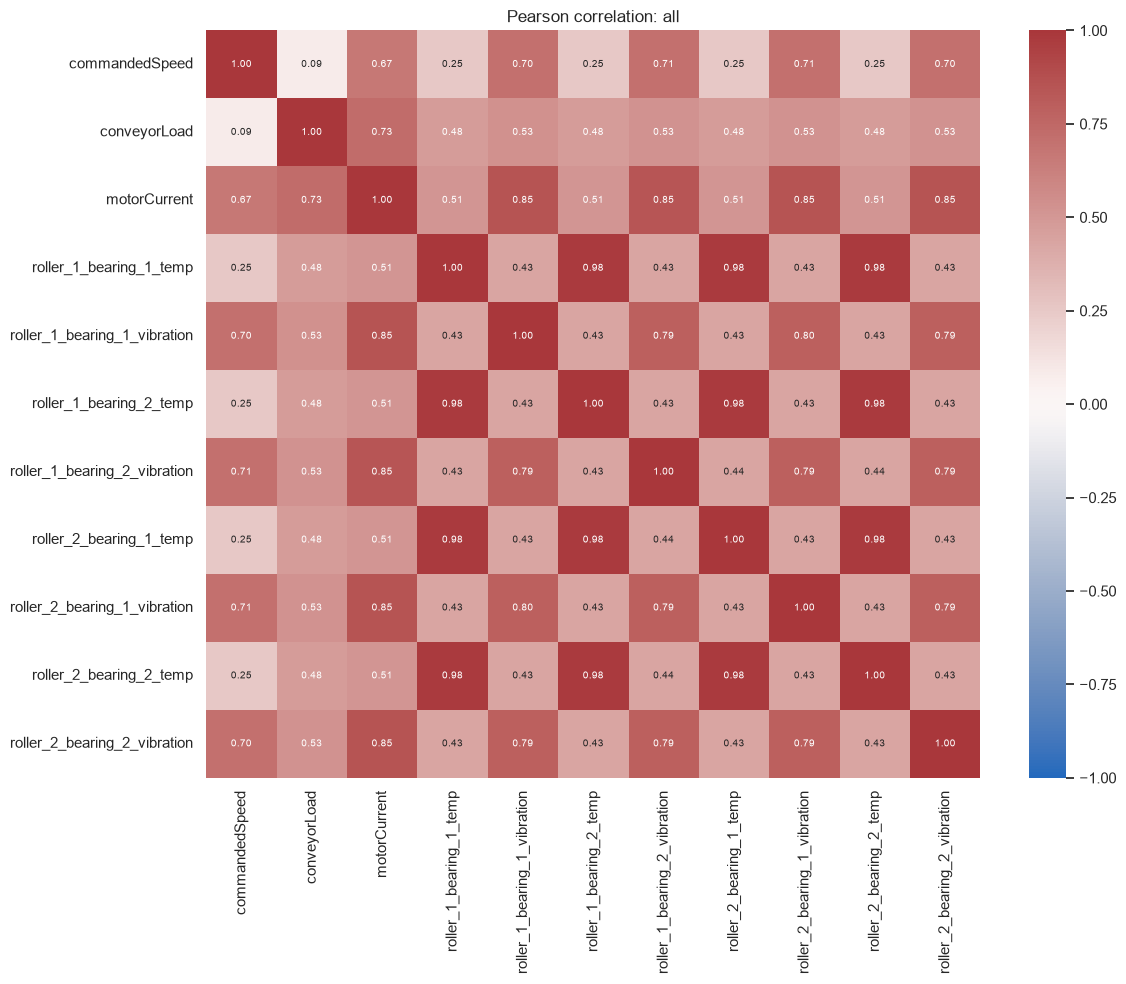

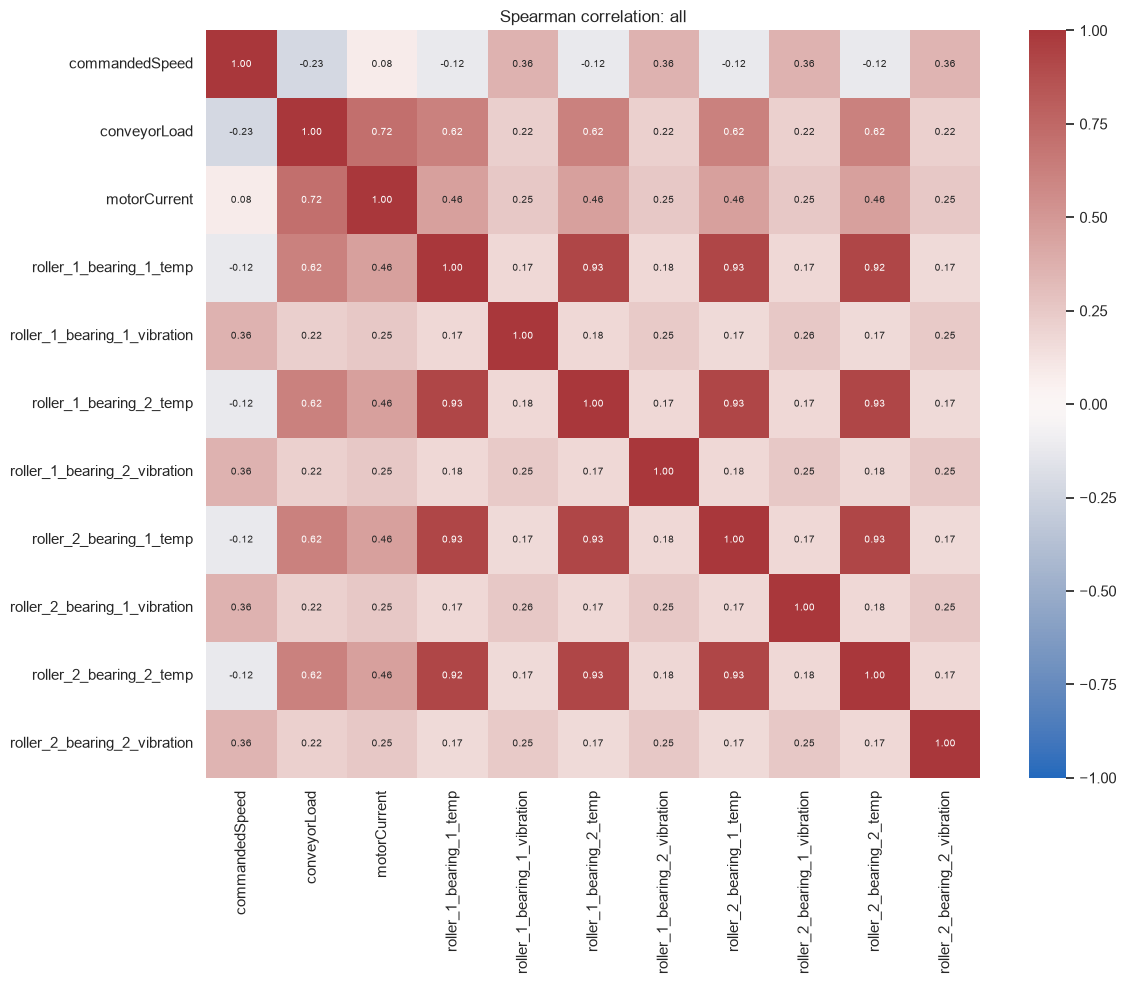

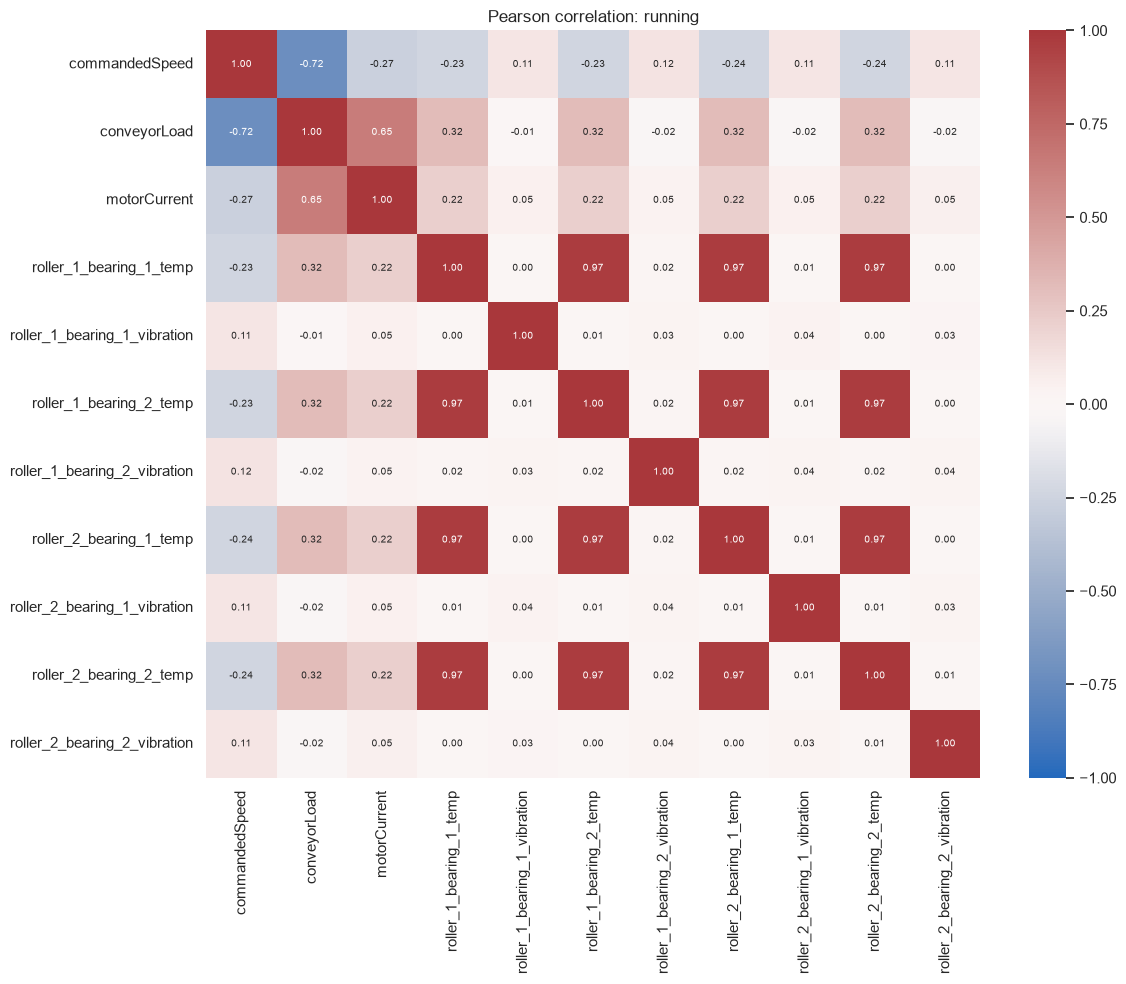

correlation
roller_1_bearing_1_temp roller_1_bearing_2_temp     0.971342
roller_1_bearing_2_temp roller_2_bearing_2_temp     0.971140
roller_2_bearing_1_temp roller_2_bearing_2_temp     0.970892
roller_1_bearing_1_temp roller_2_bearing_1_temp     0.970815
roller_1_bearing_2_temp roller_2_bearing_1_temp     0.970782
roller_1_bearing_1_temp roller_2_bearing_2_temp     0.970616
commandedSpeed          conveyorLoad               -0.721669
conveyorLoad            motorCurrent                0.647893
                        roller_2_bearing_1_temp     0.317612
                        roller_1_bearing_2_temp     0.317048
                        roller_1_bearing_1_temp     0.316522
                        roller_2_bearing_2_temp     0.315537
commandedSpeed          motorCurrent               -0.267288
                        roller_2_bearing_1_temp    -0.236094
                        roller_2_bearing_2_temp    -0.235123

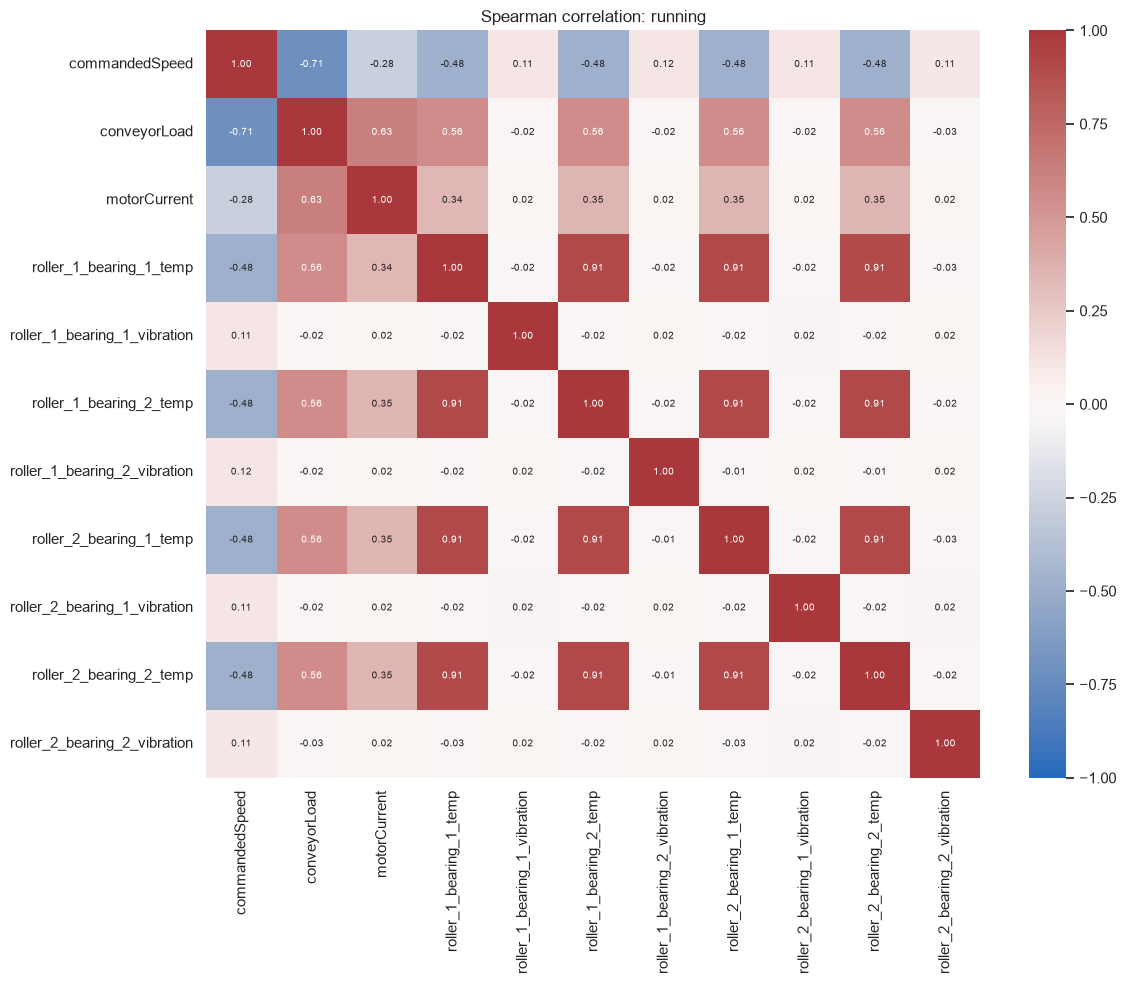

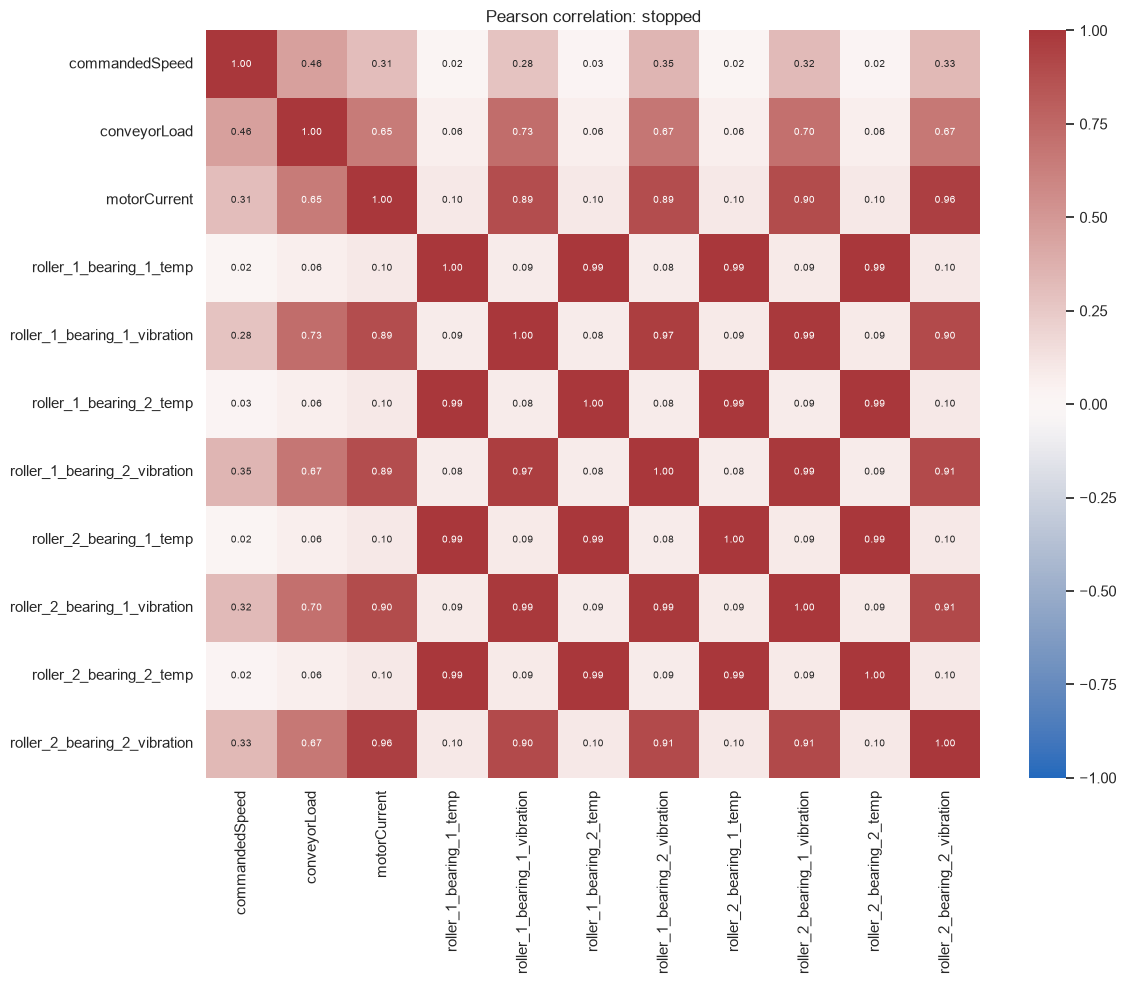

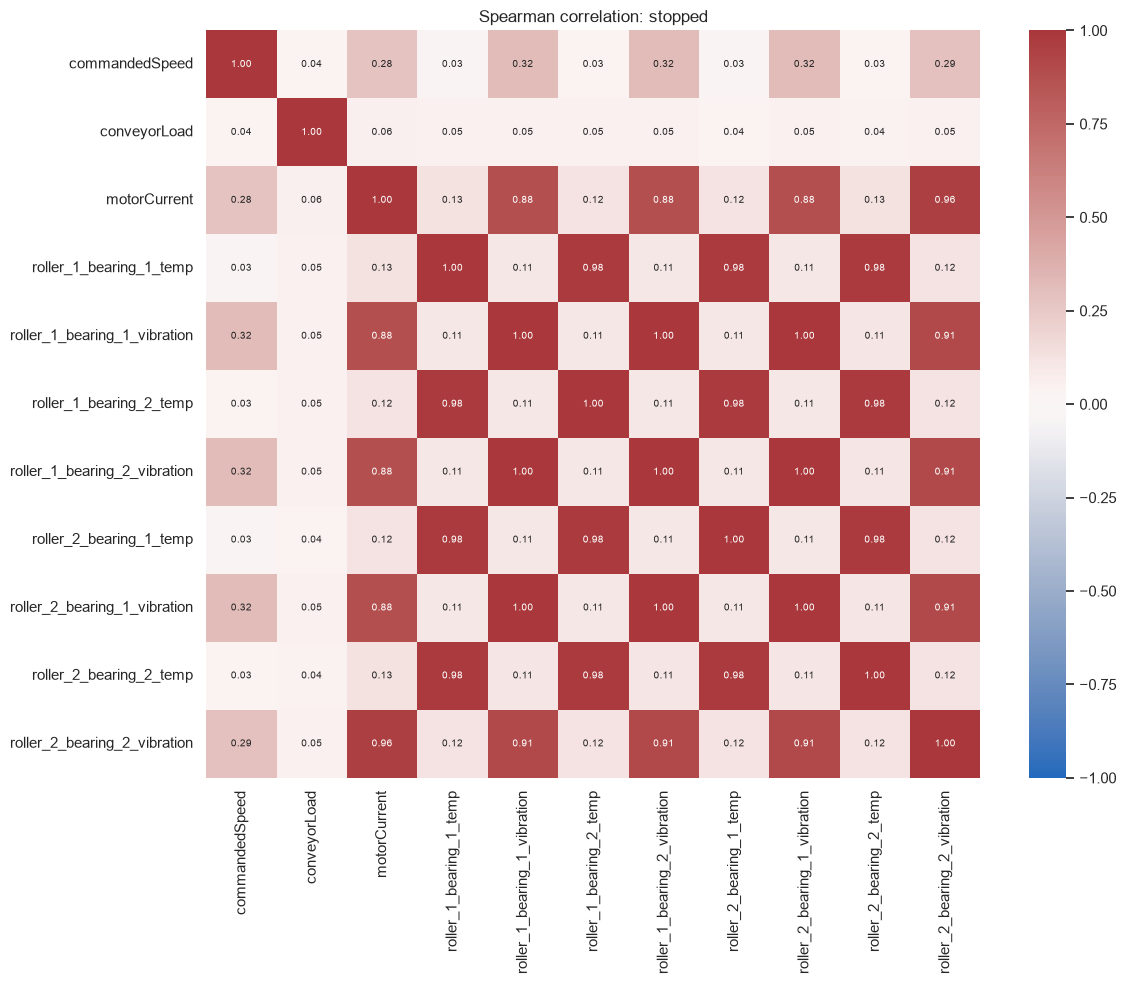

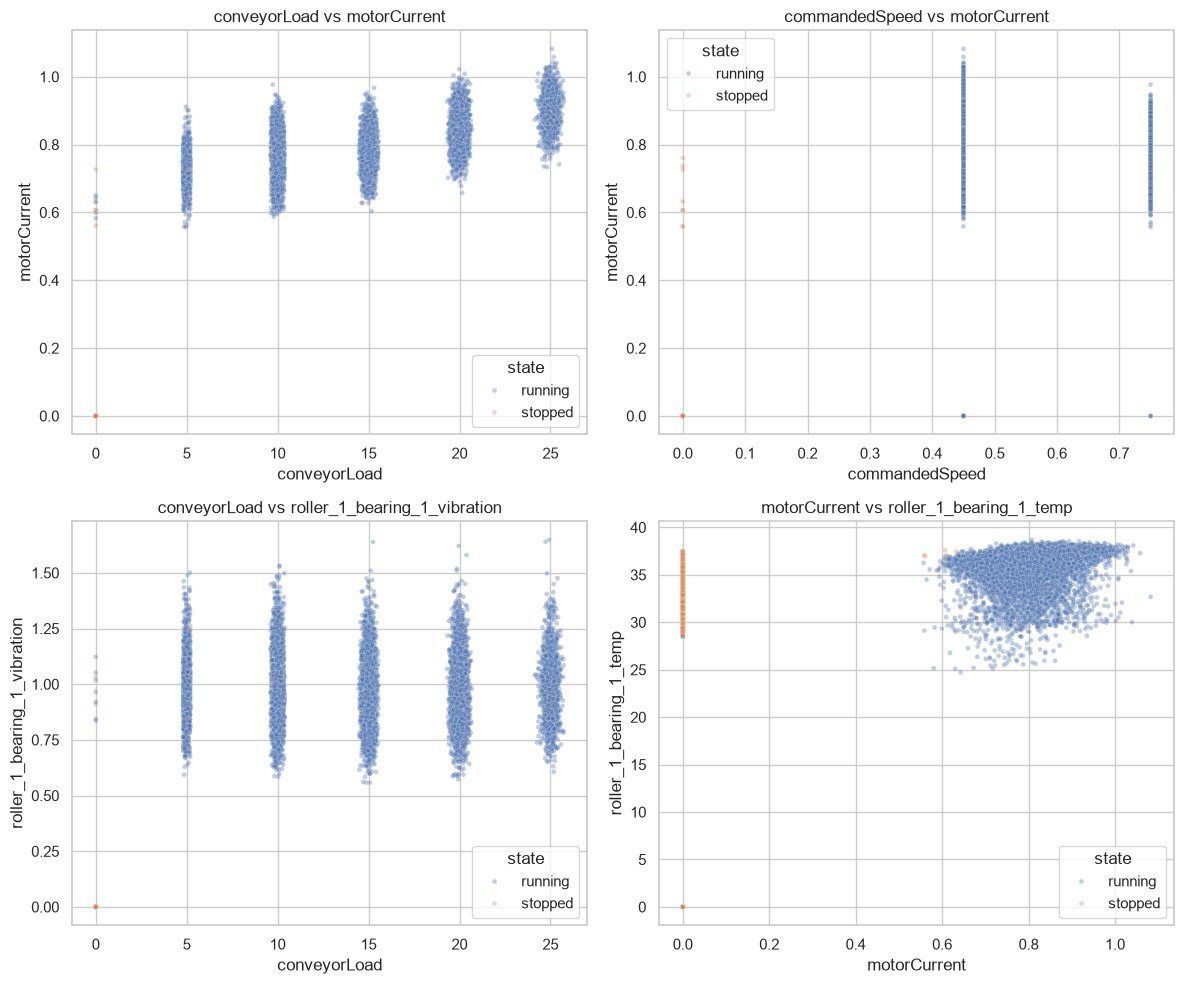

,x,y,lag_observations,correlation
30,conveyorLoad,motorCurrent,0,0.552740
79,motorCurrent,roller_1_bearing_1_temp,-12,0.051045


Lag sign indicates the shift applied to y; this is association, not causation.


In [13]:
for label, subset in [("all", df), ("running", df.loc[state.eq(1)]),
                      ("stopped", df.loc[state.eq(0)])]:
    if len(subset) < 30:
        print("Skipping", label, "correlation: fewer than 30 rows")
        continue
    for method in ("pearson", "spearman"):
        corr = subset[features].corr(method=method, min_periods=30)
        fig, ax = plt.subplots(figsize=(12, 10))
        sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1,
                    annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
        ax.set_title(f"{method.title()} correlation: {label}")
        plt.tight_layout()
        plt.show()
        if label == "running" and method == "pearson":
            pairs = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
            display(pairs.reindex(pairs.abs().sort_values(ascending=False).index)
                    .head(15).rename("correlation").to_frame())

pair_list = [("conveyorLoad", "motorCurrent"),
             ("commandedSpeed", "motorCurrent"),
             ("conveyorLoad", "roller_1_bearing_1_vibration"),
             ("motorCurrent", "roller_1_bearing_1_temp")]
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, (x, y) in zip(axes.flat, pair_list):
    if x in df and y in df:
        sample = df[[x, y, "state"]].dropna()
        if len(sample) > 15000:
            sample = sample.sample(15000, random_state=7)
        sns.scatterplot(data=sample, x=x, y=y, hue="state", alpha=.35, s=12, ax=ax)
        ax.set_title(f"{x} vs {y}")
plt.tight_layout()
plt.show()

# Lagged associations are exploratory only; inspect one long uninterrupted running segment.
run_parts = [p for _, p in running_rows.groupby(running_rows["segment_id"]) if len(p)]
if run_parts:
    lag_part = max(run_parts, key=len)
    lag_pairs = [("conveyorLoad", "motorCurrent"),
                 ("motorCurrent", "roller_1_bearing_1_temp")]
    lag_rows = []
    for x, y in lag_pairs:
        for lag in range(-30, 31):
            shifted = lag_part[y].shift(lag)
            pair = pd.concat([lag_part[x], shifted], axis=1).dropna()
            lag_rows.append({"x": x, "y": y, "lag_observations": lag,
                             "correlation": pair.iloc[:, 0].corr(pair.iloc[:, 1])})
    lag_corr = pd.DataFrame(lag_rows)
    display(lag_corr.loc[lag_corr.groupby(["x", "y"])["correlation"].apply(
        lambda s: s.abs().idxmax())].sort_values(["x", "y"]))
    print("Lag sign indicates the shift applied to y; this is association, not causation.")


## I. Compare bearing locations

Compare the four locations without assuming identical baselines. Units are not
provided. Persistent differences are investigation leads and may reflect operating
context or calibration as well as machinery behaviour.

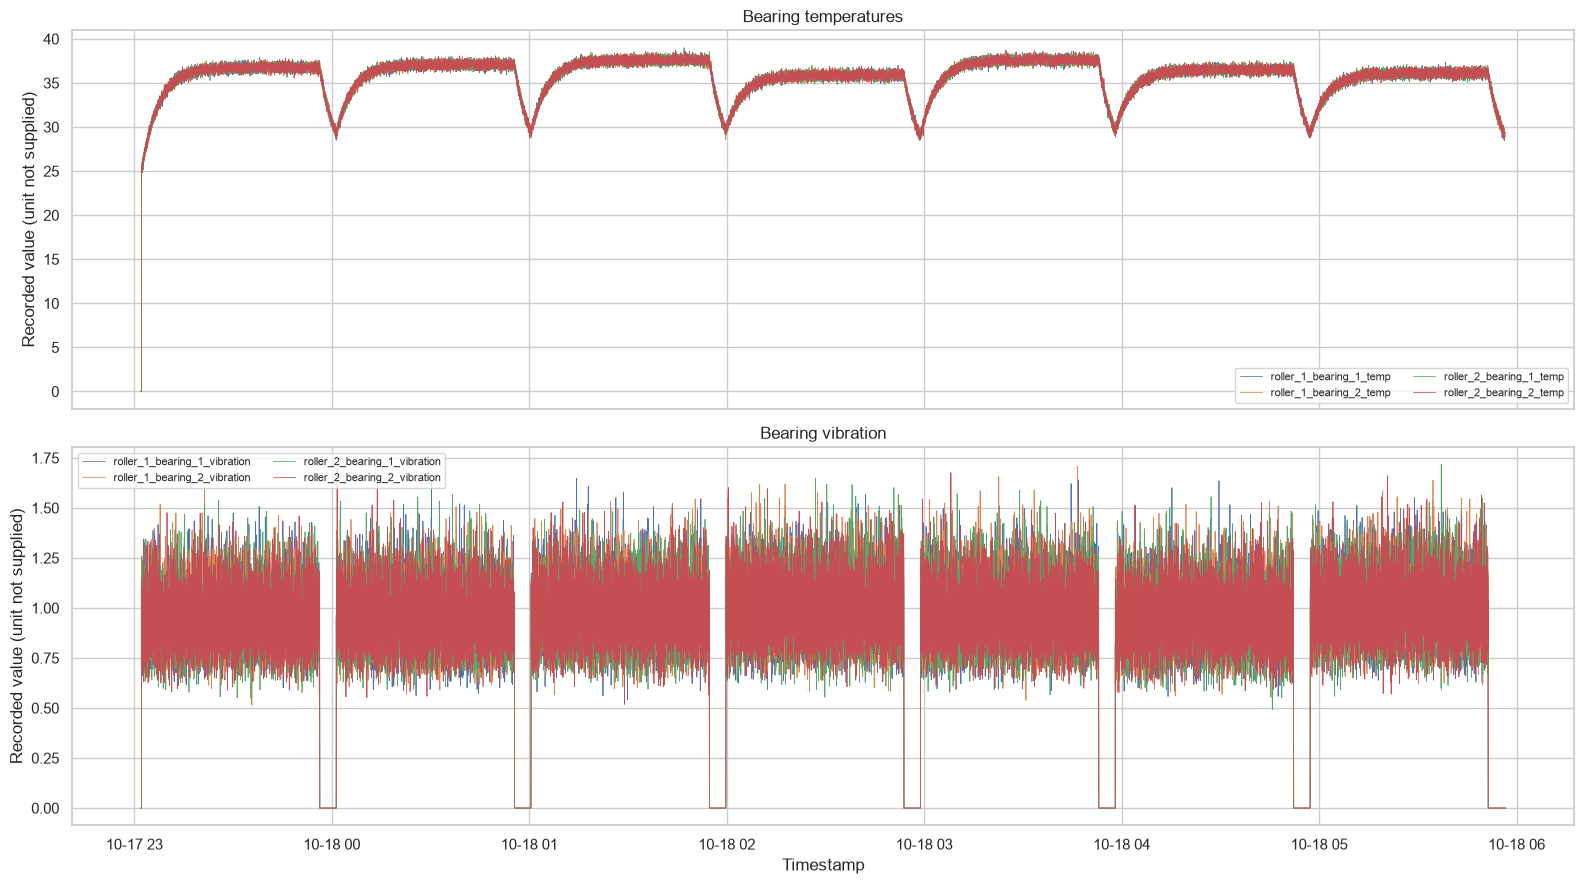

,state,bearing,signal,n,median,std,p95
0,running,roller_1_bearing_1,temp,22701,36.4130,1.7571,37.7951
1,running,roller_1_bearing_1,vibration,22701,0.9592,0.1478,1.2250
2,running,roller_1_bearing_2,temp,22701,36.4147,1.7536,37.7842
3,running,roller_1_bearing_2,vibration,22701,0.9576,0.1497,1.2329
4,running,roller_2_bearing_1,temp,22701,36.4167,1.7556,37.7945
5,running,roller_2_bearing_1,vibration,22701,0.9583,0.1483,1.2288
6,running,roller_2_bearing_2,temp,22701,36.4161,1.7570,37.7818
7,running,roller_2_bearing_2,vibration,22701,0.9590,0.1482,1.2278
8,stopped,roller_1_bearing_1,temp,2151,32.1111,3.4891,36.2731
9,stopped,roller_1_bearing_1,vibration,2151,0.0000,0.0655,0.0000


In [14]:
temp_tags = [f"{b}_temp" for b in BEARINGS if f"{b}_temp" in df]
vib_tags = [f"{b}_vibration" for b in BEARINGS if f"{b}_vibration" in df]
fig, axes = plt.subplots(2, 1, figsize=(16, 9), sharex=True)
for ax, cols, title in zip(axes, [temp_tags, vib_tags],
                           ["Bearing temperatures", "Bearing vibration"]):
    for col in cols:
        ax.plot(df.index, df[col], linewidth=.55, label=col)
    ax.set(title=title, ylabel="Recorded value (unit not supplied)")
    ax.legend(ncol=2, fontsize=8)
axes[-1].set_xlabel("Timestamp")
plt.tight_layout()
plt.show()

bearing_rows = []
for state_value, state_name in [(1, "running"), (0, "stopped")]:
    subset = df.loc[state.eq(state_value)]
    for bearing in BEARINGS:
        for kind in ("temp", "vibration"):
            col = f"{bearing}_{kind}"
            if col in subset:
                bearing_rows.append({
                    "state": state_name, "bearing": bearing, "signal": kind,
                    "n": subset[col].count(), "median": subset[col].median(),
                    "std": subset[col].std(), "p95": subset[col].quantile(.95)})
display(pd.DataFrame(bearing_rows).round(4))

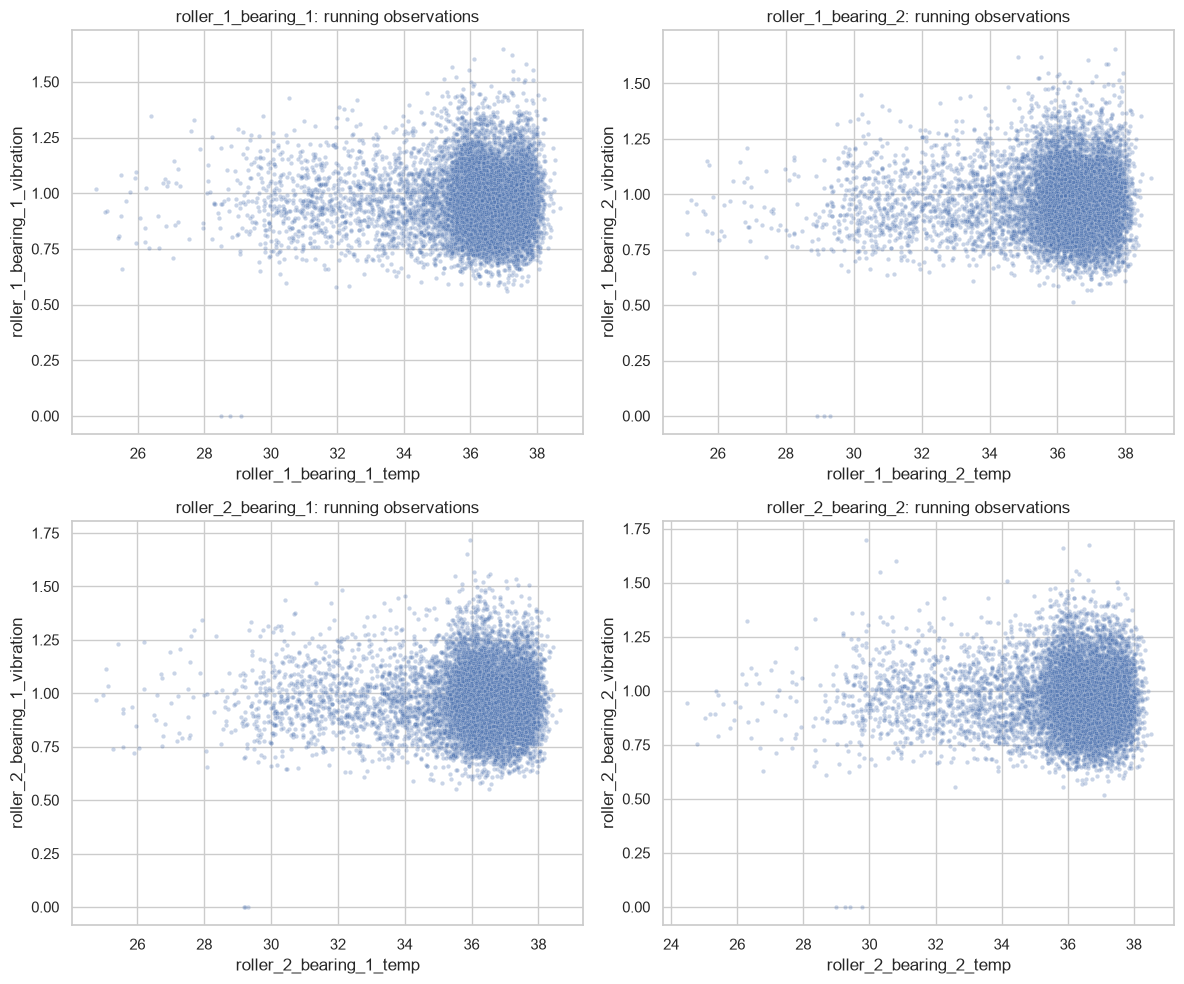

In [15]:
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, bearing in zip(axes.flat, BEARINGS):
    temp, vibration = f"{bearing}_temp", f"{bearing}_vibration"
    pair = df.loc[state.eq(1), [temp, vibration]].dropna()
    if len(pair) > 10000:
        pair = pair.sample(10000, random_state=7)
    sns.scatterplot(data=pair, x=temp, y=vibration, alpha=.3, s=10, ax=ax)
    ax.set_title(f"{bearing}: running observations")
plt.tight_layout()
plt.show()

## J. Candidate scenario analysis

There is no explicit scenario identifier in the export. Candidate labels below are
assigned by observed running-period order and compared with scheduled speed; this
is an inference, not a confirmed label. `conveyorLoad` units/meaning are unknown,
so it is weak evidence. Configured 3,240-second durations are not treated as exact.

Explicit scenario column: False
Observed running periods: 7 | scheduled scenarios: 7


,run_order,candidate,expected_mass_range,spawn_interval_s,start,end,running_s,observations,expected_speed,observed_speed_median,speed_matches,load_median,evidence
0,1,S1 light / nominal,5.5-6 kg,3.0,2026-10-17 23:02:09.535,2026-10-17 23:56:16.647,3247.112,3236,0.45,0.45,True,14.972400,order + speed support
1,2,S2 medium / nominal,8.5-9.5 kg,2.5,2026-10-18 00:01:19.883,2026-10-18 00:55:27.455,3247.572,3244,0.45,0.45,True,15.385450,order + speed support
2,3,S3 heavy / nominal,12-13 kg,2.0,2026-10-18 01:00:30.682,2026-10-18 01:54:39.883,3249.201,3248,0.45,0.45,True,20.204314,order + speed support
3,4,S4 medium / higher speed,8.5-9.5 kg,2.5,2026-10-18 01:59:43.109,2026-10-18 02:53:46.129,3243.020,3238,0.75,0.75,True,5.185493,order + speed support
4,5,S5 light / higher throughput,5.5-6 kg,2.0,2026-10-18 02:58:49.347,2026-10-18 03:52:58.041,3248.694,3249,0.45,0.45,True,20.200439,order + speed support
5,6,S6 medium / slower throughput,8.5-9.5 kg,3.5,2026-10-18 03:58:01.260,2026-10-18 04:52:11.820,3250.560,3248,0.45,0.45,True,10.356760,order + speed support
6,7,S7 heavy / higher speed,12-13 kg,2.0,2026-10-18 04:57:15.589,2026-10-18 05:51:17.605,3242.016,3238,0.75,0.75,True,9.971767,order + speed support


Scenario-level medians:


tag,commandedSpeed,conveyorLoad,motorCurrent,roller_1_bearing_1_temp,roller_1_bearing_1_vibration,roller_1_bearing_2_temp,roller_1_bearing_2_vibration,roller_2_bearing_1_temp,roller_2_bearing_1_vibration,roller_2_bearing_2_temp,roller_2_bearing_2_vibration
candidate,,,,,,,,,,,
S1 light / nominal,0.45,14.972,0.778,36.507,0.933,36.500,0.939,36.512,0.939,36.513,0.935
S2 medium / nominal,0.45,15.385,0.814,36.905,0.944,36.909,0.948,36.897,0.951,36.907,0.945
S3 heavy / nominal,0.45,20.204,0.863,37.427,0.966,37.420,0.960,37.435,0.962,37.423,0.962
S4 medium / higher speed,0.75,5.185,0.758,35.726,0.984,35.706,0.982,35.708,0.982,35.711,0.982
S5 light / higher throughput,0.45,20.200,0.862,37.416,0.964,37.411,0.962,37.421,0.961,37.411,0.963
S6 medium / slower throughput,0.45,10.357,0.751,36.322,0.936,36.322,0.926,36.314,0.931,36.335,0.940
S7 heavy / higher speed,0.75,9.972,0.782,35.928,0.990,35.947,0.988,35.942,0.987,35.933,0.987


Scenario-level standard deviations:


tag,commandedSpeed,conveyorLoad,motorCurrent,roller_1_bearing_1_temp,roller_1_bearing_1_vibration,roller_1_bearing_2_temp,roller_1_bearing_2_vibration,roller_2_bearing_1_temp,roller_2_bearing_1_vibration,roller_2_bearing_2_temp,roller_2_bearing_2_vibration
candidate,,,,,,,,,,,
S1 light / nominal,0.0,1.587,0.056,2.391,0.143,2.391,0.142,2.394,0.142,2.398,0.145
S2 medium / nominal,0.0,2.590,0.062,1.563,0.145,1.558,0.145,1.559,0.144,1.558,0.145
S3 heavy / nominal,0.0,2.605,0.062,1.628,0.144,1.624,0.148,1.629,0.144,1.627,0.146
S4 medium / higher speed,0.0,2.513,0.061,1.261,0.151,1.258,0.153,1.258,0.152,1.261,0.152
S5 light / higher throughput,0.0,2.591,0.063,1.724,0.151,1.713,0.152,1.713,0.151,1.715,0.145
S6 medium / slower throughput,0.0,2.555,0.061,1.391,0.144,1.392,0.143,1.381,0.145,1.398,0.144
S7 heavy / higher speed,0.0,1.733,0.055,1.380,0.148,1.374,0.154,1.384,0.151,1.379,0.152


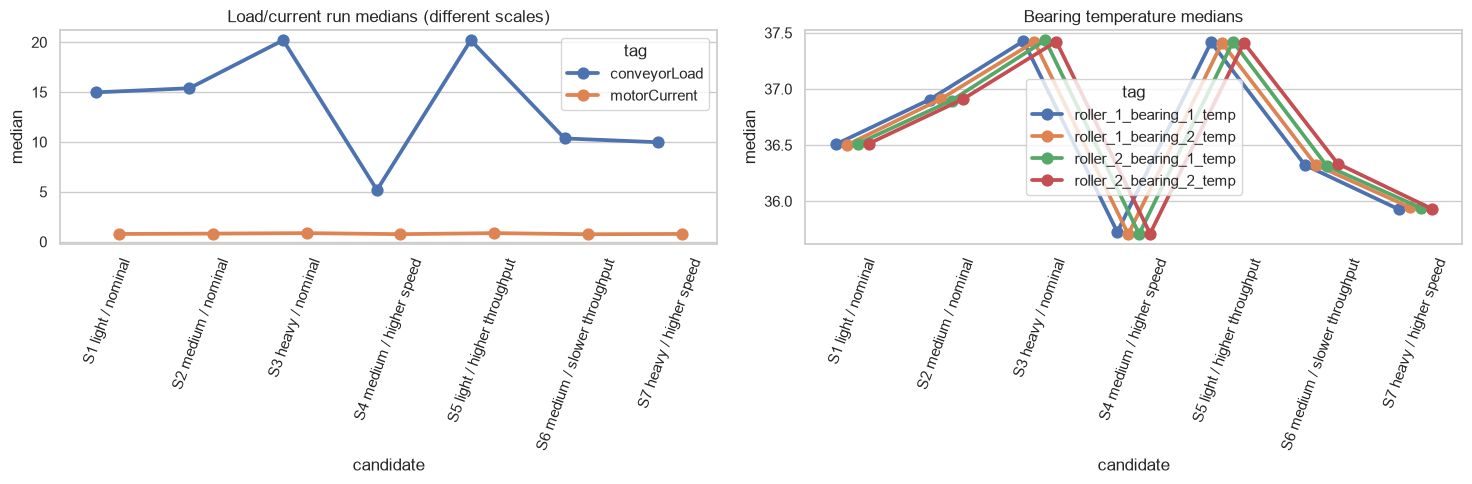

In [16]:
plan = [
    ("S1 light / nominal", .45, "5.5-6 kg", 3.0),
    ("S2 medium / nominal", .45, "8.5-9.5 kg", 2.5),
    ("S3 heavy / nominal", .45, "12-13 kg", 2.0),
    ("S4 medium / higher speed", .75, "8.5-9.5 kg", 2.5),
    ("S5 light / higher throughput", .45, "5.5-6 kg", 2.0),
    ("S6 medium / slower throughput", .45, "8.5-9.5 kg", 3.5),
    ("S7 heavy / higher speed", .75, "12-13 kg", 2.0),
]
run_periods = periods.loc[periods["state"].eq("running")].sort_values("start").reset_index(drop=True)
scenario_rows = []
for i, p in run_periods.iterrows():
    name, expected_speed, expected_mass, spawn_interval = plan[i] if i < len(plan) else (f"Unmapped run {i+1}", np.nan, "unknown", np.nan)
    observed = p["median_speed"]
    match = pd.notna(observed) and pd.notna(expected_speed) and np.isclose(observed, expected_speed, atol=.03)
    scenario_rows.append({
        "run_order": i + 1, "candidate": name, "expected_mass_range": expected_mass,
        "spawn_interval_s": spawn_interval, "start": p["start"], "end": p["end"],
        "running_s": p["duration_s"], "observations": p["observations"],
        "expected_speed": expected_speed, "observed_speed_median": observed,
        "speed_matches": bool(match), "load_median": p["median_load"],
        "evidence": "order + speed support" if match else "order-only/weak; verify in run logs",
    })
scenario_candidates = pd.DataFrame(scenario_rows)
print("Explicit scenario column:", any("scenario" in c.lower() for c in raw.columns))
print("Observed running periods:", len(run_periods), "| scheduled scenarios:", len(plan))
display(scenario_candidates)

scenario_metrics = []
for i, p in run_periods.iterrows():
    sub = df.loc[(df.index >= p["start"]) & (df.index <= p["end"]) & state.eq(1)]
    name = plan[i][0] if i < len(plan) else f"Run period {i+1}"
    for col in features:
        scenario_metrics.append({"candidate": name, "tag": col, "n": sub[col].count(),
                                 "median": sub[col].median(), "std": sub[col].std()})
scenario_metrics = pd.DataFrame(scenario_metrics)
print("Scenario-level medians:")
display(scenario_metrics.pivot(index="candidate", columns="tag", values="median").round(3))
print("Scenario-level standard deviations:")
display(scenario_metrics.pivot(index="candidate", columns="tag", values="std").round(3))

if len(run_periods):
    fig, axes = plt.subplots(1, 2, figsize=(15, 5))
    med = scenario_metrics[scenario_metrics["tag"].isin(["conveyorLoad", "motorCurrent"])]
    sns.pointplot(data=med, x="candidate", y="median", hue="tag", dodge=.25, ax=axes[0])
    axes[0].tick_params(axis="x", rotation=70)
    axes[0].set_title("Load/current run medians (different scales)")
    temps = scenario_metrics[scenario_metrics["tag"].isin(temp_tags)]
    sns.pointplot(data=temps, x="candidate", y="median", hue="tag", dodge=.35, ax=axes[1])
    axes[1].tick_params(axis="x", rotation=70)
    axes[1].set_title("Bearing temperature medians")
    plt.tight_layout()
    plt.show()

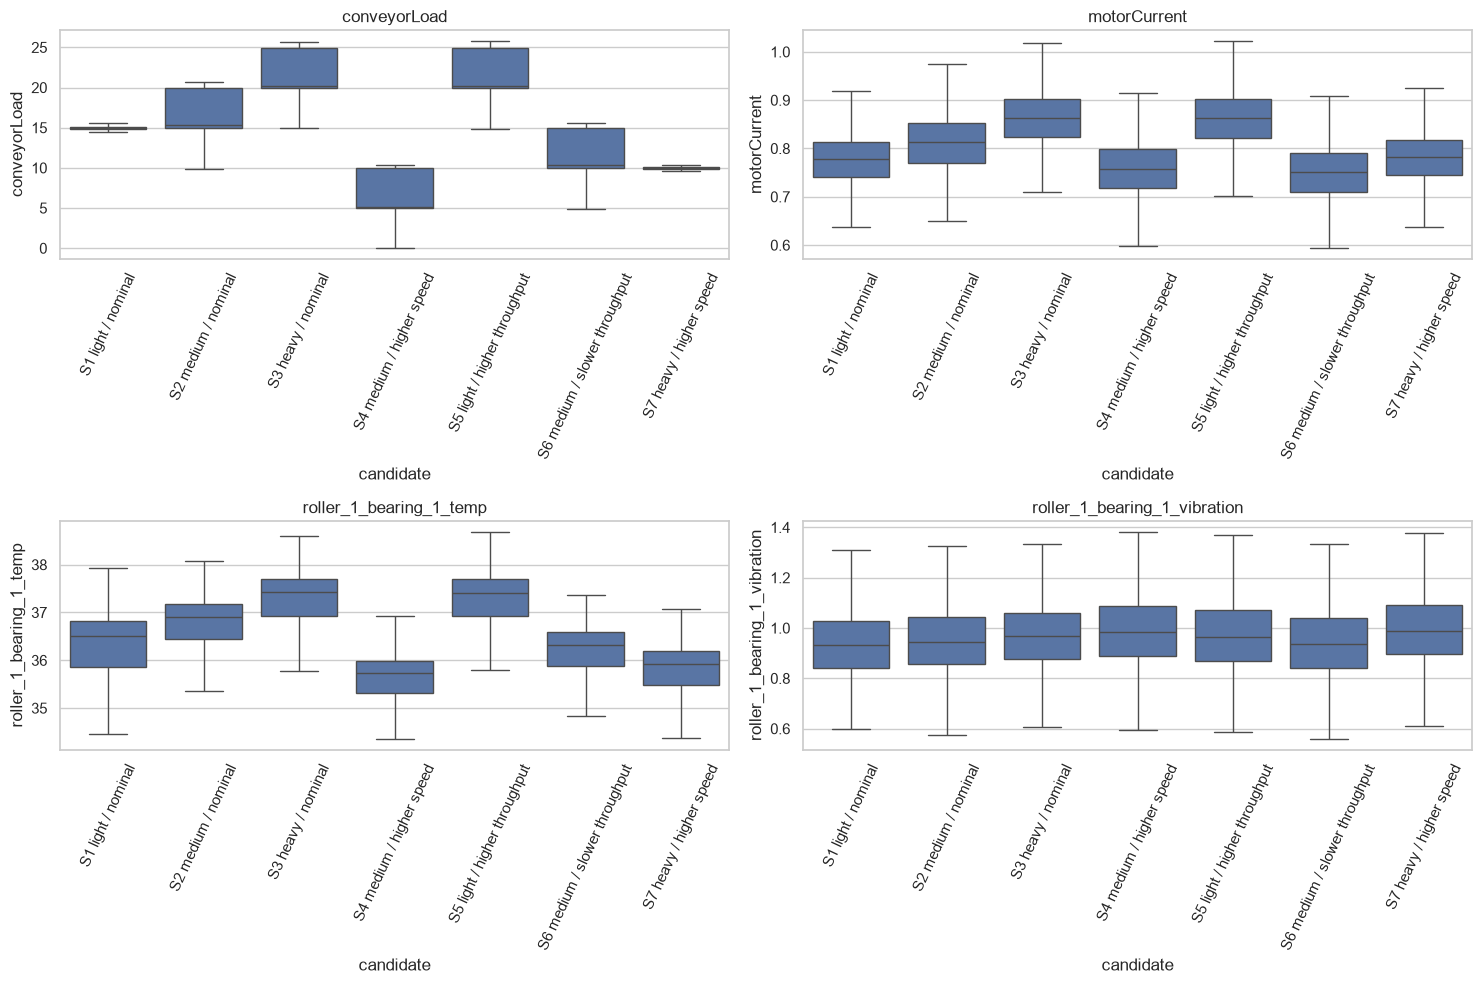

Motor-off periods between/around candidate runs; these may combine drain, settling, and cooling:


,start,end,duration_s,observations
0,2026-10-17 23:01:54.524,2026-10-17 23:02:08.533,14.009,15
1,2026-10-17 23:56:17.647,2026-10-18 00:01:18.882,301.235,302
2,2026-10-18 00:55:28.456,2026-10-18 01:00:29.682,301.226,302
3,2026-10-18 01:54:40.883,2026-10-18 01:59:42.109,301.226,302
4,2026-10-18 02:53:47.130,2026-10-18 02:58:48.346,301.216,302
5,2026-10-18 03:52:59.042,2026-10-18 03:58:00.260,301.218,302
6,2026-10-18 04:52:12.820,2026-10-18 04:57:14.589,301.769,302
7,2026-10-18 05:51:18.611,2026-10-18 05:56:42.189,323.578,324


In [17]:
scenario_frames = []
for i, p in run_periods.iterrows():
    name = plan[i][0] if i < len(plan) else f"Run period {i+1}"
    sub = df.loc[(df.index >= p["start"]) & (df.index <= p["end"]) & state.eq(1), features].copy()
    sub["candidate"] = name
    scenario_frames.append(sub)
scenario_data = pd.concat(scenario_frames) if scenario_frames else pd.DataFrame()
box_signals = [c for c in ["conveyorLoad", "motorCurrent",
                           "roller_1_bearing_1_temp",
                           "roller_1_bearing_1_vibration"] if c in scenario_data]
if len(scenario_data) and box_signals:
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    for ax, col in zip(axes.flat, box_signals):
        sns.boxplot(data=scenario_data, x="candidate", y=col, showfliers=False, ax=ax)
        ax.set_title(col)
        ax.tick_params(axis="x", rotation=65)
    plt.tight_layout()
    plt.show()

print("Motor-off periods between/around candidate runs; these may combine drain, settling, and cooling:")
display(periods.loc[periods["state"].eq("stopped"),
                    ["start", "end", "duration_s", "observations"]].reset_index(drop=True))

## K. Modelling-readiness assessment (no training)

These are initial options to validate against simulation/PLC/SCADA records and
sensor engineering limits before constructing training data.

In [18]:
print("DATA-DRIVEN NOTES")
print(f"Unique-time rows: {len(df):,}; source rows: {len(raw):,}; "
      f"repeated-timestamp rows: {int(parsed_time.duplicated(keep=False).sum()):,}.")
print(f"Median interval: {median_interval:.3f}s; maximum: {positive_dt.max():.3f}s; "
      f"gaps >1.5x median: {int(gap_mask.sum())}.")
print(f"Running periods: {len(run_periods)}; missing analysis tag values: {int(quality['missing'].sum())}.")
print("Flat-lined tags:", quality.index[quality["unique_non_null"].le(1)].tolist())
print("Candidate numeric inputs:", features)
print("Use isMotorRunning first as a segmentation/context variable; test it as a feature separately.")
print("\\nStarting hypotheses:")
print("1. Use motor-running to segment steady-running sequences; compare including it as an input separately.")
print("2. Initially model steady running; evaluate startup/shutdown and stopped/cooldown separately.")
print("3. Never construct sequences across state changes, long gaps, invalid records, or split boundaries.")
print("4. Decide resampling/imputation after examining sampling regularity and missingness; retain raw timestamps.")
print("5. Compare RobustScaler with standard scaling; fit preprocessing on training data only.")
print(f"6. Benchmark 30/60/120 observation windows (~{30*median_interval:.0f}/"
      f"{60*median_interval:.0f}/{120*median_interval:.0f} seconds at median cadence).")
print("7. Represent all confirmed normal scenarios in training; reserve a scenario only for a deliberate generalisation test.")
print("8. Without verified fault labels, precision/recall/F1 and true fault-detection performance are not measurable.")
print("9. Obtain units, engineering ranges, sensor health/calibration, scenario logs, export bounds, and verified normal/fault periods.")

DATA-DRIVEN NOTES
Unique-time rows: 24,852; source rows: 297,876; repeated-timestamp rows: 297,859.
Median interval: 1.001s; maximum: 7.205s; gaps >1.5x median: 20.
Running periods: 7; missing analysis tag values: 0.
Flat-lined tags: []
Candidate numeric inputs: ['commandedSpeed', 'conveyorLoad', 'motorCurrent', 'roller_1_bearing_1_temp', 'roller_1_bearing_1_vibration', 'roller_1_bearing_2_temp', 'roller_1_bearing_2_vibration', 'roller_2_bearing_1_temp', 'roller_2_bearing_1_vibration', 'roller_2_bearing_2_temp', 'roller_2_bearing_2_vibration']
Use isMotorRunning first as a segmentation/context variable; test it as a feature separately.
\nStarting hypotheses:
1. Use motor-running to segment steady-running sequences; compare including it as an input separately.
2. Initially model steady running; evaluate startup/shutdown and stopped/cooldown separately.
3. Never construct sequences across state changes, long gaps, invalid records, or split boundaries.
4. Decide resampling/imputation afte

## L. Chronological validation and leakage controls

Split chronologically before fitting transforms or creating windows. Never randomly
split individual rows or overlapping windows. Keep the final test set untouched;
scenario-based generalisation is an additional experiment once labels are verified.

In [19]:
print("Suggested starting design (fractions are not fitted decisions):")
print("- Use earlier ~70% of verified normal segments for training, next ~15% for validation, latest ~15% for test.")
print("- Cut segments at split boundaries and purge at least one full window on each side.")
print("- Do not cross state transitions, large gaps, invalid runs, or split boundaries when creating windows.")
print("- Fit imputation and scaling on training only; apply unchanged to validation/test.")
print("- Use validation for settings and threshold calibration; do not consult test during selection.")
print("- If scenario labels are confirmed, report chronological results and a separate held-out-scenario stress test.")
print("- Without labels, inspect high-error windows and false-alarm burden on verified normal data; these do not replace fault metrics.")

Suggested starting design (fractions are not fitted decisions):
- Use earlier ~70% of verified normal segments for training, next ~15% for validation, latest ~15% for test.
- Cut segments at split boundaries and purge at least one full window on each side.
- Do not cross state transitions, large gaps, invalid runs, or split boundaries when creating windows.
- Fit imputation and scaling on training only; apply unchanged to validation/test.
- Use validation for settings and threshold calibration; do not consult test during selection.
- If scenario labels are confirmed, report chronological results and a separate held-out-scenario stress test.
- Without labels, inspect high-error windows and false-alarm burden on verified normal data; these do not replace fault metrics.


## M. Evidence summary and pre-training checklist

The summary is generated from the loaded data. It reports recorded patterns and
limitations, not confirmed faults.

In [20]:
print("DATASET OVERVIEW")
print("Source:", CSV_PATH.resolve())
print(f"Raw shape: {raw.shape}; unique-time rows: {len(df):,}; "
      f"period: {df.index.min()} to {df.index.max()} ({df.index.max()-df.index.min()}).")
print(f"Median interval: {median_interval:.3f}s; gaps >1.5x median: {int(gap_mask.sum())}; "
      f"maximum interval: {positive_dt.max():.3f}s.")
print(f"Repeated-timestamp rows: {int(parsed_time.duplicated(keep=False).sum()):,}; "
      f"conflicting timestamp groups: {int(conflicts.any(axis=1).sum()):,}; "
      f"exact duplicate rows: {int(raw.duplicated().sum()):,}.")
print(f"Running/stopped unique-time observations: {int(state.eq(1).sum()):,}/"
      f"{int(state.eq(0).sum()):,}; running periods: {len(run_periods)}.")
print("\\nLIMITATIONS")
print("- Scenario labels are inferred from order/telemetry, not a CSV field.")
print("- Units, timezone, engineering limits, and requested export window are unknown.")
print("- Statistical outlier fences do not confirm faults; no readings were deleted.")
print("- No verified anomaly labels were supplied; fault metrics/threshold validity cannot be established.")
print("\\nBEFORE TRAINING")
for item in [
    "Confirm export bounds and historian timestamp/timezone semantics.",
    "Verify units, engineering ranges, sensor calibration, and PLC tag meanings.",
    "Confirm duplicate-snapshot pattern and scenario boundaries with source logs.",
    "Investigate missing, flat-lined, and suspicious values; document any correction/exclusion.",
    "Choose explicit treatment for running, transition, stopped, and cooldown states.",
    "Choose resampling/imputation only after sampling and gap review.",
    "Create chronological, segment-safe splits before fitting preprocessing or making windows.",
    "Define how normal periods and any verified fault labels will be established.",
    "Do not train or set an arbitrary anomaly threshold in this EDA notebook.",
]:
    print("[ ]", item)

DATASET OVERVIEW
Source: C:\UnityProjects\DigitalTwin-Project\ml\conveyor_historian_export.csv
Raw shape: (297876, 13); unique-time rows: 24,852; period: 2026-10-17 23:01:54.524000 to 2026-10-18 05:56:42.189000 (0 days 06:54:47.665000).
Median interval: 1.001s; gaps >1.5x median: 20; maximum interval: 7.205s.


Repeated-timestamp rows: 297,859; conflicting timestamp groups: 24,669; exact duplicate rows: 47,969.
Running/stopped unique-time observations: 22,701/2,151; running periods: 7.
\nLIMITATIONS
- Scenario labels are inferred from order/telemetry, not a CSV field.
- Units, timezone, engineering limits, and requested export window are unknown.
- Statistical outlier fences do not confirm faults; no readings were deleted.
- No verified anomaly labels were supplied; fault metrics/threshold validity cannot be established.
\nBEFORE TRAINING
[ ] Confirm export bounds and historian timestamp/timezone semantics.
[ ] Verify units, engineering ranges, sensor calibration, and PLC tag meanings.
[ ] Confirm duplicate-snapshot pattern and scenario boundaries with source logs.
[ ] Investigate missing, flat-lined, and suspicious values; document any correction/exclusion.
[ ] Choose explicit treatment for running, transition, stopped, and cooldown states.
[ ] Choose resampling/imputation only after samplin